<a href="https://colab.research.google.com/github/LR-Lemon/Milestone-II/blob/main/notebooks/02_model_a_volatility_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model A: Supervised Volatility Forecasting

## Objective

This notebook develops and evaluates the supervised learning component of the project, focusing on forecasting forward realized volatility of the S&P 500.

Using the market characteristics engineered during Model B's feature-engineering stage, the analysis predicts **forward 5-day realized volatility** as its primary objective, with **10-day and 20-day forecasting horizons** included as robustness checks.

The analysis compares two predictor specifications:

- **Market-only:** Observable market characteristics, including VIX levels and changes, historical realized volatility, return skewness, and kurtosis.
- **Market + HMM:** The same market characteristics supplemented by filtered regime probabilities generated by Model B.

The primary objective is to determine whether latent market regime information identified through a Gaussian Hidden Markov Model provides incremental predictive value beyond observable market characteristics.

The forecasting process includes:

1. Loading the previously engineered market features and Model B's HMM outputs.
2. Merging observable market characteristics with filtered regime probabilities.
3. Constructing forward 5-, 10-, and 20-day realized-volatility targets.
4. Defining market-only and regime-enhanced predictor sets.
5. Partitioning the dataset chronologically into training, validation, and independent test periods, with boundary purges.
6. Developing a persistence baseline and estimating Ridge Regression and XGBoost forecasting models.
7. Selecting model hyperparameters using validation performance.
8. Evaluating forecasting accuracy using Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE).
9. Comparing model performance against persistence and measuring the incremental contribution of HMM regime probabilities.
10. Conducting HAC-adjusted statistical tests to evaluate differences in out-of-sample squared forecasting loss.

## Outputs

The notebook produces the following analytical outputs:

1. **Integrated Modeling Dataset:** A chronologically aligned dataset combining engineered market predictors, filtered HMM regime probabilities, and forward realized-volatility targets for three forecasting horizons.

2. **Forecasting Models:** A persistence baseline, Ridge Regression, and XGBoost, with market-only and regime-enhanced specifications for both supervised methods.

3. **Out-of-Sample Forecasts:** Predicted and observed realized volatility for the 5-, 10-, and 20-day horizons over the independent test period.

4. **Performance Evaluation:** Consolidated RMSE and MAE results, relative improvements over persistence, and comparisons of incremental forecasting performance from incorporating HMM information.

5. **Statistical Comparison:** HAC-adjusted Diebold–Mariano-style forecast comparison results examining differences in expected squared forecasting loss.

6. **Diagnostic Visualizations:** Target distributions, predictor correlations, chronological data partitions, forecasting performance charts, feature importance, and statistical significance visualizations.

7. **Final Assessment:** A consolidated evaluation of forecasting accuracy, the incremental predictive contribution of HMM regime information, and methodological limitations.

The visualizations are exported as individual high-resolution PNG files for inclusion in the final Milestone II report and appendices.

## Role in the Overall Project

The overall project follows a **two-stage modeling framework**, integrating unsupervised market regime identification with supervised volatility forecasting.

**Model B — Unsupervised Market Regime Identification**

Model B applies a Gaussian Hidden Markov Model to observable market characteristics to identify three latent market regimes: Calm, Transition, and Stressed.

The model generates filtered probabilities describing the likelihood of each regime based on information available up to the corresponding trading date. These probabilities provide an interpretable representation of changing market conditions and serve as additional predictors in Model A.

**Model A — Supervised Volatility Forecasting**

Model A extends the analysis by forecasting future realized volatility using a persistence baseline, Ridge Regression, and XGBoost.

The supervised models are evaluated using observable market characteristics alone and again with filtered HMM regime probabilities.

Comparing these specifications across multiple forecasting horizons allows the project to assess whether inferred market states contain predictive information beyond the characteristics used to identify them.

The combined framework distinguishes between the ability to **identify meaningful market regimes** and the ability to **demonstrate their incremental forecasting value**. This distinction addresses the project's central research question without assuming that regime classification necessarily improves volatility forecasting.

---------------------------------------------------------

## Section 1 - Environment Setup and Data Loading

This section establishes the computational environment and loads
the datasets required for supervised volatility forecasting.

The preparation process includes:

- **Repository initialization:** Accessing the standardized GitHub
  project directory within Google Colab.
- **Dependency management:** Installing the required Python libraries
  from the project's `requirements.txt` file.
- **Library imports:** Loading packages required for preprocessing,
  supervised model estimation, statistical evaluation, and visualization.
- **Dataset loading:** Importing the engineered market features and
  filtered HMM regime probabilities generated by Model B.
- **Data inspection:** Verifying dataset dimensions, variable types,
  observation dates, and missing values before model development.

The two input datasets provide historical market characteristics
and inferred market regime information for forecasting forward
S&P 500 realized volatility over 5, 10, and 20 trading days.

This section establishes a reproducible modeling environment
while ensuring consistency with the outputs produced by
Part 0: Feature Engineering and Model B: Market Regime Identification.

### Section 1.1 - Repository Configuration and Dependencies

In [1]:
# --------------------------------------------------
# 1.1 Repository Configuration and Dependencies
# --------------------------------------------------

import sys
import subprocess
from pathlib import Path

# GitHub repository configuration
REPO_URL = "https://github.com/LR-Lemon/Milestone-II.git"
PROJECT_ROOT = Path("/content/Milestone-II")

# Clone repository if it does not already exist
if not (PROJECT_ROOT / ".git").exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(PROJECT_ROOT)],
        check=True
    )

# Install project dependencies
requirements_path = PROJECT_ROOT / "requirements.txt"

if not requirements_path.is_file():
    raise FileNotFoundError(
        f"Requirements file not found: {requirements_path}"
    )

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-r",
        str(requirements_path)
    ],
    check=True
)

# Record repository version
git_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=True
).stdout.strip()

# Display environment information
print("Environment setup completed successfully.\n")
print("Project root:", PROJECT_ROOT)
print("Python version:", sys.version.split()[0])
print("Git commit:", git_commit)
print("Requirements file:", requirements_path)

Environment setup completed successfully.

Project root: /content/Milestone-II
Python version: 3.13.16
Git commit: 9000b6226e0d3ee8d9c3ca5b07f1c34d10743b88
Requirements file: /content/Milestone-II/requirements.txt


### Section 1.2 - Import Required Libraries

In [2]:
# --------------------------------------------------
# 1.2 Import Required Libraries
# --------------------------------------------------

# Numerical computation and data manipulation
import numpy as np
import pandas as pd
from itertools import product

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns

# Feature preprocessing and model pipelines
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Supervised learning: Ridge Regression
from sklearn.linear_model import Ridge

# Supervised learning: Support Vector Regression
from sklearn.svm import SVR

# Supervised learning: XGBoost
from xgboost import XGBRegressor

# Model selection and time-series cross-validation
from sklearn.model_selection import (
    ParameterGrid,
    TimeSeriesSplit
)

# Forecast evaluation
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

# Statistical inference
import statsmodels.api as sm

# Display preferences
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

### Section 1.3 - Load the Model A Input Datasets

This section loads the two input datasets required for supervised volatility forecasting, produced during the previous stages of the project.

The datasets include:

- **Engineered Market Features:** The complete set of historical S&P 500 and VIX market characteristics developed during Part 0: Feature Engineering.
- **Model B HMM Output:** The market regime classifications and filtered probabilities generated by the Gaussian Hidden Markov Model (HMM).

The initial inspection includes:

- **Dataset dimensions:** Confirming the number of observations and variables.
- **Variable structure:** Examining column names and data types.
- **Temporal coverage:** Identifying the first and last trading dates.
- **Data preview:** Inspecting the initial observations to confirm successful loading.

Both datasets are loaded without modifying their values. Additional integrity checks, date alignment, and feature integration will be performed in Section 2.

These inputs support the evaluation of whether inferred market regime information improves supervised forecasts of forward S&P 500 realized volatility.

In [3]:
# --------------------------------------------------
# 1.3 Load the Model A Input Datasets
# --------------------------------------------------

# Define dataset paths
MARKET_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "engineered_features"
    / "market_full_features_2000_2025.parquet"
)

HMM_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "regime_features"
    / "model_b_hmm_full_output.parquet"
)

# Verify file availability
for path in [MARKET_DATA_PATH, HMM_DATA_PATH]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required dataset not found: {path}"
        )

# Load datasets
market_features = pd.read_parquet(MARKET_DATA_PATH)
hmm_output = pd.read_parquet(HMM_DATA_PATH)

# Display initial dataset information
for name, df in [
    ("Engineered Market Features", market_features),
    ("Model B HMM Output", hmm_output)
]:
    print(f"\n{name} Loaded Successfully")
    print("-" * 50)

    print("Dataset shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nObservation period:")
    print("Start:", df["Date"].min())
    print("End:", df["Date"].max())

    print("\nFirst five observations:")
    display(df.head())


Engineered Market Features Loaded Successfully
--------------------------------------------------
Dataset shape: (6519, 23)

Columns:
['Date', 'SP500_Open', 'SP500_High', 'SP500_Low', 'SP500_Close', 'SP500_Adj_Close', 'SP500_Volume', 'VIX_Open', 'VIX_High', 'VIX_Low', 'VIX_Close', 'SP500_Log_Return', 'VIX_Level', 'VIX_Change', 'Realized_Vol_5D', 'Realized_Vol_10D', 'Realized_Vol_20D', 'Return_Skew_5D', 'Return_Skew_10D', 'Return_Skew_20D', 'Return_Kurt_5D', 'Return_Kurt_10D', 'Return_Kurt_20D']

Data types:
Date                datetime64[ns]
SP500_Open                 float64
SP500_High                 float64
SP500_Low                  float64
SP500_Close                float64
SP500_Adj_Close            float64
SP500_Volume                 int64
VIX_Open                   float64
VIX_High                   float64
VIX_Low                    float64
VIX_Close                  float64
SP500_Log_Return           float64
VIX_Level                  float64
VIX_Change                 floa

,Date,SP500_Open,SP500_High,SP500_Low,SP500_Close,SP500_Adj_Close,SP500_Volume,VIX_Open,VIX_High,VIX_Low,VIX_Close,SP500_Log_Return,VIX_Level,VIX_Change,Realized_Vol_5D,Realized_Vol_10D,Realized_Vol_20D,Return_Skew_5D,Return_Skew_10D,Return_Skew_20D,Return_Kurt_5D,Return_Kurt_10D,Return_Kurt_20D
0,2000-02-01,"1,394.4600","1,412.4900","1,384.7900","1,409.2800","1,409.2800",981000000,24.4300,24.7400,23.2900,23.4500,0.0106,23.4500,-1.5000,0.3115,0.2548,0.2636,-0.2534,-0.1560,-0.5230,0.3986,0.3141,0.4541
1,2000-02-02,"1,409.2800","1,420.6100","1,403.4900","1,409.1200","1,409.1200",1038600000,23.0200,24.7400,22.6200,23.1200,-0.0001,23.1200,-0.3300,0.3095,0.2546,0.2233,-0.4654,-0.1424,-0.2181,0.8041,0.3277,0.5606
2,2000-02-03,"1,409.1200","1,425.7800","1,398.5200","1,424.9700","1,424.9700",1146500000,22.7200,23.7300,21.9300,22.0100,0.0112,22.0100,-1.1100,0.3137,0.2633,0.2266,-1.1525,-0.4509,-0.2915,1.8414,0.0363,0.3915
3,2000-02-04,"1,424.9700","1,435.9100","1,420.6300","1,424.3700","1,424.3700",1045100000,20.7700,21.7700,20.6900,21.5400,-0.0004,21.5400,-0.4700,0.1649,0.2632,0.2266,0.7997,-0.5077,-0.2753,0.2310,0.0880,0.3819
4,2000-02-07,"1,424.3700","1,427.1500","1,413.3300","1,424.2400","1,424.2400",918100000,22.9700,23.2700,22.7900,22.7900,-0.0001,22.7900,1.2500,0.0965,0.2167,0.2048,0.6123,-0.6333,-0.5036,-3.2962,2.3529,0.8049



Model B HMM Output Loaded Successfully
--------------------------------------------------
Dataset shape: (6519, 17)

Columns:
['Date', 'SP500_Close', 'VIX_Level', 'VIX_Change', 'Realized_Vol_20D', 'Return_Skew_20D', 'Return_Kurt_20D', 'HMM_State', 'Regime', 'P_Calm', 'P_Transition', 'P_Stressed', 'Filtered_P_Calm', 'Filtered_P_Transition', 'Filtered_P_Stressed', 'Regime_Confidence', 'Filtered_Regime_Confidence']

Data types:
Date                          datetime64[ns]
SP500_Close                          float64
VIX_Level                            float64
VIX_Change                           float64
Realized_Vol_20D                     float64
Return_Skew_20D                      float64
Return_Kurt_20D                      float64
HMM_State                              int64
Regime                                object
P_Calm                               float64
P_Transition                         float64
P_Stressed                           float64
Filtered_P_Calm               

,Date,SP500_Close,VIX_Level,VIX_Change,Realized_Vol_20D,Return_Skew_20D,Return_Kurt_20D,HMM_State,Regime,P_Calm,P_Transition,P_Stressed,Filtered_P_Calm,Filtered_P_Transition,Filtered_P_Stressed,Regime_Confidence,Filtered_Regime_Confidence
0,2000-02-01,"1,409.2800",23.4500,-1.5000,0.2636,-0.5230,0.4541,2,Transition,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000
1,2000-02-02,"1,409.1200",23.1200,-0.3300,0.2233,-0.2181,0.5606,2,Transition,0.0000,0.9999,0.0001,0.0000,0.9964,0.0036,0.9999,0.9964
2,2000-02-03,"1,424.9700",22.0100,-1.1100,0.2266,-0.2915,0.3915,2,Transition,0.0000,0.9999,0.0001,0.0000,0.9968,0.0032,0.9999,0.9968
3,2000-02-04,"1,424.3700",21.5400,-0.4700,0.2266,-0.2753,0.3819,2,Transition,0.0000,0.9999,0.0001,0.0000,0.9971,0.0029,0.9999,0.9971
4,2000-02-07,"1,424.2400",22.7900,1.2500,0.2048,-0.5036,0.8049,2,Transition,0.0000,1.0000,0.0000,0.0000,0.9993,0.0007,1.0000,0.9993


**Key Observation**

Both input datasets were successfully loaded and inspected.

- **Engineered Market Features:** Contains 6,519 observations and 23 variables, including historical S&P 500 and VIX market information and engineered volatility, skewness, and kurtosis measures.
- **Model B HMM Output:** Contains 6,519 observations and 17 variables, including inferred market regime classifications, regime probabilities, and model confidence measures.
- **Observation period:** Both datasets cover February 1, 2000, through December 31, 2025.
- **Temporal structure:** Both datasets use a datetime-formatted `Date` variable, providing a common key for integration.
- **Regime predictors:** Three filtered probabilities (`Filtered_P_Calm`, `Filtered_P_Transition`, and `Filtered_P_Stressed`) are available for the regime-enhanced forecasting specification.

The initial inspection confirms that both datasets contain the required information for Model A.

The next section will verify data integrity, chronological alignment, and probability consistency before integrating the datasets into a unified modeling framework.

## Section 2 - Data Integrity and Integration

This section validates and integrates the engineered market features and Model B HMM outputs to construct a unified dataset for supervised volatility forecasting.

The validation and integration process includes:

- **Data integrity:** Examining missing values, duplicate observations, and variable types across both datasets.
- **Temporal alignment:** Verifying that market features and HMM outputs correspond to the same trading dates.
- **Probability validation:** Confirming that filtered regime probabilities are within valid bounds and sum to one.
- **Dataset integration:** Merging the three filtered HMM probabilities with the engineered market features.
- **Post-integration verification:** Checking that the merged dataset preserves the expected observations and variable structure.

The resulting dataset will support two forecasting specifications: market-only predictors and market indicators supplemented by filtered HMM regime probabilities.

These checks establish the reliability of the input data before constructing forward realized volatility targets and developing supervised learning models.

### Section 2.1 - Dataset Integrity and Missing Values

The assessment includes:

- **Missing values:** Identifying null observations across all variables.
- **Duplicate records:** Checking for repeated rows and trading dates.
- **Data types:** Verifying that the date and numerical variables have appropriate formats.
- **Numerical validity:** Identifying infinite values in numerical columns.
- **Chronological order:** Confirming that observations are arranged in ascending trading-date order.

In [4]:
# --------------------------------------------------
# 2.1 Dataset Integrity and Missing Values
# --------------------------------------------------

# Define datasets for validation
datasets = {
    "Engineered Market Features": market_features,
    "Model B HMM Output": hmm_output
}

integrity_results = []

for name, df in datasets.items():

    # Identify numerical columns
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    # Calculate integrity indicators
    missing_values = df.isna().sum()
    infinite_values = np.isinf(df[numeric_cols]).sum()

    duplicate_rows = df.duplicated().sum()
    duplicate_dates = df["Date"].duplicated().sum()

    date_sorted = df["Date"].is_monotonic_increasing
    date_type_valid = pd.api.types.is_datetime64_any_dtype(
        df["Date"]
    )

    # Store results
    integrity_results.append({
        "Dataset": name,
        "Observations": len(df),
        "Variables": df.shape[1],
        "Missing Values": int(missing_values.sum()),
        "Infinite Values": int(infinite_values.sum()),
        "Duplicate Rows": int(duplicate_rows),
        "Duplicate Dates": int(duplicate_dates),
        "Valid Date Type": date_type_valid,
        "Chronologically Sorted": date_sorted
    })

    # Report missing values, if present
    print(f"\n{name}")
    print("-" * 55)

    if missing_values.sum() > 0:
        print("Columns with missing values:")
        display(missing_values[missing_values > 0].to_frame("Count"))
    else:
        print("No missing values detected.")

    # Report infinite values, if present
    if infinite_values.sum() > 0:
        print("\nColumns with infinite values:")
        display(
            infinite_values[infinite_values > 0]
            .to_frame("Count")
        )
    else:
        print("No infinite numerical values detected.")

# Consolidated integrity summary
integrity_summary = pd.DataFrame(integrity_results)

print("\nDataset Integrity Summary")
print("-" * 55)

display(integrity_summary)


Engineered Market Features
-------------------------------------------------------
No missing values detected.
No infinite numerical values detected.

Model B HMM Output
-------------------------------------------------------
No missing values detected.
No infinite numerical values detected.

Dataset Integrity Summary
-------------------------------------------------------


,Dataset,Observations,Variables,Missing Values,Infinite Values,Duplicate Rows,Duplicate Dates,Valid Date Type,Chronologically Sorted
0,Engineered Market Features,6519,23,0,0,0,0,True,True
1,Model B HMM Output,6519,17,0,0,0,0,True,True


### Section 2.2 - Trading Date Alignment

This subsection evaluates the temporal alignment between the Engineered Market Features dataset and the Model B HMM Output.

Although both datasets contain 6,519 observations covering the same period, identical dimensions do not necessarily guarantee that their trading dates match.

The assessment includes:

- **Date coverage:** Comparing the earliest and latest trading dates.
- **Date correspondence:** Identifying observations present in one dataset but absent from the other.
- **Sequential alignment:** Verifying that trading dates correspond in chronological order.
- **Integration readiness:** Confirming that both datasets can be merged using a one-to-one relationship on the `Date` variable.

Successful alignment ensures that the filtered HMM regime probabilities correspond to the correct market observations without introducing mismatched or missing records.

In [5]:
# --------------------------------------------------
# 2.2 Trading Date Alignment
# --------------------------------------------------

# Extract trading dates
market_dates = pd.DatetimeIndex(market_features["Date"])
hmm_dates = pd.DatetimeIndex(hmm_output["Date"])

# Identify unmatched trading dates
market_only_dates = market_dates.difference(hmm_dates)
hmm_only_dates = hmm_dates.difference(market_dates)

# Verify sequential alignment
dates_match_in_order = market_dates.equals(hmm_dates)

# Consolidated alignment summary
alignment_summary = pd.DataFrame({
    "Validation Check": [
        "Market feature observations",
        "HMM output observations",
        "Market start date",
        "HMM start date",
        "Market end date",
        "HMM end date",
        "Dates exclusive to market features",
        "Dates exclusive to HMM output",
        "Dates match in chronological order"
    ],
    "Result": [
        len(market_dates),
        len(hmm_dates),
        market_dates.min().date(),
        hmm_dates.min().date(),
        market_dates.max().date(),
        hmm_dates.max().date(),
        len(market_only_dates),
        len(hmm_only_dates),
        dates_match_in_order
    ]
})

print("Trading Date Alignment Summary")
print("-" * 55)
display(alignment_summary)

# Display unmatched dates if present
if len(market_only_dates) > 0:
    print("\nDates exclusive to Market Features:")
    display(pd.DataFrame({"Date": market_only_dates}))

if len(hmm_only_dates) > 0:
    print("\nDates exclusive to Model B HMM:")
    display(pd.DataFrame({"Date": hmm_only_dates}))

# Confirm integration readiness
assert len(market_only_dates) == 0, \
    "Market Features contain unmatched trading dates."

assert len(hmm_only_dates) == 0, \
    "HMM Output contains unmatched trading dates."

assert dates_match_in_order, \
    "Trading dates are not aligned in chronological order."

print("\nTrading date alignment verified successfully.")

Trading Date Alignment Summary
-------------------------------------------------------


,Validation Check,Result
0,Market feature observations,6519
1,HMM output observations,6519
2,Market start date,2000-02-01
3,HMM start date,2000-02-01
4,Market end date,2025-12-31
5,HMM end date,2025-12-31
6,Dates exclusive to market features,0
7,Dates exclusive to HMM output,0
8,Dates match in chronological order,True



Trading date alignment verified successfully.


**Key Observations**

- **Observation coverage:** Both datasets contain 6,519 trading dates, spanning February 1, 2000, through December 31, 2025.
- **Unmatched dates:** No trading dates were exclusive to either dataset.
- **Chronological alignment:** Both datasets contain identical trading dates arranged in the same ascending order.
- **Integration readiness:** The datasets support a one-to-one merge using the `Date` variable, without requiring additional date adjustments or exclusions.

These findings establish that the filtered HMM probabilities can be matched to their corresponding market observations without introducing temporal mismatches.

### Section 2.3 - HMM Probability Validation

The assessment focuses on three HMM-derived variables:

- **Filtered_P_Calm:** Filtered probability of the Calm market regime.
- **Filtered_P_Transition:** Filtered probability of the Transition market regime.
- **Filtered_P_Stressed:** Filtered probability of the Stressed market regime.

The validation process includes:

- **Probability bounds:** Confirming that each probability falls between 0 and 1.
- **Probability normalization:** Verifying that the three probabilities sum to approximately 1 for every trading date.
- **Probability completeness:** Confirming that all observations contain valid filtered probabilities.
- **Distribution inspection:** Examining the minimum, maximum, and average probability for each regime.

**Filtered probabilities** are used instead of smoothed probabilities because
the filtering procedure conditions on market observations available up to the corresponding trading date.

This distinction is important for limiting look-ahead bias when using regime probabilities as predictors of future realized volatility.

In [6]:
# --------------------------------------------------
# 2.3 HMM Probability Validation
# --------------------------------------------------

# Define filtered regime probability columns
filtered_prob_cols = [
    "Filtered_P_Calm",
    "Filtered_P_Transition",
    "Filtered_P_Stressed"
]

# Extract filtered probabilities
filtered_probs = hmm_output[filtered_prob_cols].copy()

# Check probability completeness
missing_probabilities = int(filtered_probs.isna().sum().sum())

# Check probability bounds
out_of_bounds = int(
    ((filtered_probs < 0) | (filtered_probs > 1))
    .any(axis=1)
    .sum()
)

# Calculate row-wise probability sums
probability_sums = filtered_probs.sum(axis=1)

# Numerical tolerance for floating-point calculations
tolerance = 1e-6

# Identify rows with invalid probability sums
invalid_sums = int(
    (~np.isclose(probability_sums, 1.0, atol=tolerance, rtol=0))
    .sum()
)

# Summarize probability distributions
probability_summary = filtered_probs.agg(
    ["mean", "std", "min", "max"]
).T

probability_summary.index.name = "Regime Probability"

print("Filtered HMM Probability Distribution")
print("-" * 55)
display(probability_summary)

# Consolidated validation summary
validation_summary = pd.DataFrame({
    "Validation Check": [
        "Observations assessed",
        "Missing probability values",
        "Observations with out-of-bounds probabilities",
        "Observations with invalid probability sums",
        "Minimum probability sum",
        "Maximum probability sum",
        "Maximum absolute deviation from 1"
    ],
    "Result": [
        len(filtered_probs),
        missing_probabilities,
        out_of_bounds,
        invalid_sums,
        probability_sums.min(),
        probability_sums.max(),
        np.abs(probability_sums - 1).max()
    ]
})

print("\nHMM Probability Validation Summary")
print("-" * 55)
display(validation_summary)

# Assert mathematical consistency
assert missing_probabilities == 0, \
    "Missing filtered HMM probabilities detected."

assert out_of_bounds == 0, \
    "Filtered probabilities outside [0, 1] detected."

assert invalid_sums == 0, \
    "Filtered regime probabilities do not sum to 1."

print("\nFiltered HMM probability validation completed successfully.")

Filtered HMM Probability Distribution
-------------------------------------------------------


,mean,std,min,max
Regime Probability,,,,
Filtered_P_Calm,0.3312,0.4562,0.0000,1.0000
Filtered_P_Transition,0.4177,0.4712,0.0000,1.0000
Filtered_P_Stressed,0.2511,0.4185,0.0000,1.0000



HMM Probability Validation Summary
-------------------------------------------------------


,Validation Check,Result
0,Observations assessed,"6,519.0000"
1,Missing probability values,0.0000
2,Observations with out-of-bounds probabilities,0.0000
3,Observations with invalid probability sums,0.0000
4,Minimum probability sum,1.0000
5,Maximum probability sum,1.0000
6,Maximum absolute deviation from 1,0.0000



Filtered HMM probability validation completed successfully.


**Key Observation**

- **Observations assessed:** 6,519 trading days.
- **Probability completeness:** No missing filtered probability values were detected.
- **Probability bounds:** All probabilities fall within the valid interval of 0 to 1.
- **Probability normalization:** The three filtered probabilities sum to approximately 1 for every observation.
- **Probability distribution:** The Transition regime has the highest average filtered probability (0.4177), followed by Calm (0.3312) and Stressed (0.2511).
- **Probability variation:** Relatively high standard deviations indicate substantial variation in regime probabilities across trading days.

These results confirm that the filtered probabilities are mathematically valid and suitable for integration into Model A.

The three filtered probabilities will be retained as additional predictors in the regime-enhanced forecasting specification. Smoothed probabilities and historical regime labels will not be included in the primary supervised models.

### Section 2.4 - Dataset Integration

This subsection integrates the engineered market features with the filtered HMM regime probabilities generated by Model B.

The integration procedure includes:

- **Feature selection:** Extracting the three filtered regime probabilities from the Model B output.
- **Merge configuration:** Performing a one-to-one merge using the common `Date` variable.
- **Observation preservation:** Retaining the complete set of trading dates from the engineered market-feature dataset.
- **Feature preservation:** Maintaining the original market variables without modifying their values.
- **Integration validation:** Confirming that the merge does not introduce additional observations, duplicate dates, or missing regime probabilities.

Only filtered regime probabilities are incorporated into the supervised dataset. Smoothed probabilities and regime classifications are excluded from the primary predictor specifications.

The resulting dataset provides a common foundation for comparing market-only forecasting models against models supplemented by HMM-derived regime information.

In [7]:
# --------------------------------------------------
# 2.4 Dataset Integration
# --------------------------------------------------

# Select HMM-derived predictors
hmm_features = hmm_output[
    ["Date"] + filtered_prob_cols
].copy()

# Preserve the original observation count
original_observations = len(market_features)

# Merge market features with filtered HMM probabilities
model_a_df = market_features.merge(
    hmm_features,
    on="Date",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verify merge correspondence
merge_summary = model_a_df["_merge"].value_counts()

print("Dataset Integration Summary")
print("-" * 55)

display(
    merge_summary.rename_axis("Merge Status")
    .reset_index(name="Observations")
)

# Confirm no unmatched observations
assert (model_a_df["_merge"] == "both").all(), \
    "Some market observations have no matching HMM probabilities."

# Remove temporary merge indicator
model_a_df = model_a_df.drop(columns="_merge")

# Verify observation preservation
assert len(model_a_df) == original_observations, \
    "Observation count changed during integration."

# Verify date uniqueness
assert model_a_df["Date"].is_unique, \
    "Duplicate trading dates detected after integration."

# Verify regime probability completeness
assert model_a_df[filtered_prob_cols].notna().all().all(), \
    "Missing filtered probabilities detected after integration."

# Display merged dataset information
print("\nIntegrated Model A Dataset")
print("-" * 55)

print("Dataset shape:", model_a_df.shape)
print("Start date:", model_a_df["Date"].min().date())
print("End date:", model_a_df["Date"].max().date())

print("\nFirst five observations:")
display(model_a_df.head())

Dataset Integration Summary
-------------------------------------------------------


,Merge Status,Observations
0,both,6519
1,left_only,0
2,right_only,0



Integrated Model A Dataset
-------------------------------------------------------
Dataset shape: (6519, 26)
Start date: 2000-02-01
End date: 2025-12-31

First five observations:


,Date,SP500_Open,SP500_High,SP500_Low,SP500_Close,SP500_Adj_Close,SP500_Volume,VIX_Open,VIX_High,VIX_Low,VIX_Close,SP500_Log_Return,VIX_Level,VIX_Change,Realized_Vol_5D,Realized_Vol_10D,Realized_Vol_20D,Return_Skew_5D,Return_Skew_10D,Return_Skew_20D,Return_Kurt_5D,Return_Kurt_10D,Return_Kurt_20D,Filtered_P_Calm,Filtered_P_Transition,Filtered_P_Stressed
0,2000-02-01,"1,394.4600","1,412.4900","1,384.7900","1,409.2800","1,409.2800",981000000,24.4300,24.7400,23.2900,23.4500,0.0106,23.4500,-1.5000,0.3115,0.2548,0.2636,-0.2534,-0.1560,-0.5230,0.3986,0.3141,0.4541,0.0000,1.0000,0.0000
1,2000-02-02,"1,409.2800","1,420.6100","1,403.4900","1,409.1200","1,409.1200",1038600000,23.0200,24.7400,22.6200,23.1200,-0.0001,23.1200,-0.3300,0.3095,0.2546,0.2233,-0.4654,-0.1424,-0.2181,0.8041,0.3277,0.5606,0.0000,0.9964,0.0036
2,2000-02-03,"1,409.1200","1,425.7800","1,398.5200","1,424.9700","1,424.9700",1146500000,22.7200,23.7300,21.9300,22.0100,0.0112,22.0100,-1.1100,0.3137,0.2633,0.2266,-1.1525,-0.4509,-0.2915,1.8414,0.0363,0.3915,0.0000,0.9968,0.0032
3,2000-02-04,"1,424.9700","1,435.9100","1,420.6300","1,424.3700","1,424.3700",1045100000,20.7700,21.7700,20.6900,21.5400,-0.0004,21.5400,-0.4700,0.1649,0.2632,0.2266,0.7997,-0.5077,-0.2753,0.2310,0.0880,0.3819,0.0000,0.9971,0.0029
4,2000-02-07,"1,424.3700","1,427.1500","1,413.3300","1,424.2400","1,424.2400",918100000,22.9700,23.2700,22.7900,22.7900,-0.0001,22.7900,1.2500,0.0965,0.2167,0.2048,0.6123,-0.6333,-0.5036,-3.2962,2.3529,0.8049,0.0000,0.9993,0.0007


**Key Observations:**

- **Matched observations:** All 6,519 market observations were successfully matched with their corresponding HMM outputs.
- **Unmatched observations:** No unmatched trading dates were identified.
- **Dataset dimensions:** The integrated dataset contains 6,519 observations and 26 variables.
- **Feature preservation:** All 23 original market variables were retained without modification.
- **Regime integration:** Three filtered HMM probabilities were added, representing Calm, Transition, and Stressed market conditions.
- **Temporal coverage:** The integrated dataset spans February 1, 2000, through December 31, 2025.

The integration preserves the original market observations while incorporating the regime information required to evaluate its incremental contribution to volatility forecasting.

### Section 2.5 - Integrated Dataset Verification and Summary

This subsection performs a final integrity assessment of the integrated Model A dataset.

The verification process confirms:

- **Observation preservation:** The integrated dataset retains all original trading dates.
- **Feature completeness:** All required market variables and filtered regime probabilities are available.
- **Data integrity:** No missing values, duplicate trading dates, or infinite numerical values were introduced during integration.
- **Probability consistency:** The filtered probabilities continue to sum to approximately one for each observation.
- **Chronological consistency:** The dataset remains ordered by trading date.

Successful verification establishes the integrated dataset as the validated input for forward volatility target engineering.

In [8]:
# --------------------------------------------------
# 2.5 Integrated Dataset Verification and Summary
# --------------------------------------------------

# Validate numerical values
numeric_cols = model_a_df.select_dtypes(include=[np.number]).columns

# Final dataset checks
final_checks = {
    "Observations": len(model_a_df),
    "Variables": model_a_df.shape[1],
    "Missing Values": int(model_a_df.isna().sum().sum()),
    "Infinite Values": int(
        np.isinf(model_a_df[numeric_cols]).sum().sum()
    ),
    "Duplicate Dates": int(model_a_df["Date"].duplicated().sum()),
    "Chronologically Sorted": model_a_df["Date"].is_monotonic_increasing,
    "Valid HMM Probability Sums": bool(
        np.isclose(
            model_a_df[filtered_prob_cols].sum(axis=1),
            1.0,
            atol=1e-6,
            rtol=0
        ).all()
    )
}

# Display verification summary
final_summary = pd.DataFrame(
    final_checks.items(),
    columns=["Validation Check", "Result"]
)

print("Integrated Dataset Verification Summary")
print("-" * 55)

display(final_summary)

# Validate expected structure
assert len(model_a_df) == len(market_features)
assert model_a_df["Date"].is_unique
assert model_a_df["Date"].is_monotonic_increasing
assert model_a_df.isna().sum().sum() == 0
assert np.isfinite(model_a_df[numeric_cols].to_numpy()).all()
assert final_checks["Valid HMM Probability Sums"]

print("\nIntegrated Model A dataset verified successfully.")

Integrated Dataset Verification Summary
-------------------------------------------------------


,Validation Check,Result
0,Observations,6519
1,Variables,26
2,Missing Values,0
3,Infinite Values,0
4,Duplicate Dates,0
5,Chronologically Sorted,True
6,Valid HMM Probability Sums,True



Integrated Model A dataset verified successfully.


## Section 3 - Forward Volatility Target Engineering

This section constructs the supervised learning targets used to forecast future S&P 500 realized volatility.

Unlike the trailing volatility features developed during Part 0, the forecasting targets measure realized volatility over future trading-day windows.

The target engineering process includes:

- **Forecast horizon definition:** Establishing forward volatility targets over 5, 10, and 20 trading days.
- **Forward volatility calculation:** Computing realized volatility from subsequent S&P 500 daily log returns.
- **Target validation:** Verifying that calculations use future observations without incorporating them into the predictor variables.
- **Missing target assessment:** Identifying observations near the end of the dataset with insufficient future returns.
- **Distribution analysis:** Examining the statistical characteristics of the forward volatility targets.

All targets are calculated consistently across the three forecasting horizons to support direct comparisons between Ridge Regression, Support Vector Regression, and XGBoost.

The resulting targets represent the dependent variables for the supervised forecasting models.

### Section 3.1 - Define Forward Realized Volatility Targets

The forecasting targets are defined as:

- **Forward_RV_5D:** Annualized realized volatility over the next 5 trading days.
- **Forward_RV_10D:** Annualized realized volatility over the next 10 trading days.
- **Forward_RV_20D:** Annualized realized volatility over the next 20 trading days.

The forward targets are constructed independently of the predictors, which are restricted to information available on or before the forecast date.

In [10]:
# --------------------------------------------------
# 3.1 Define Forward Realized Volatility Targets
# --------------------------------------------------

# Create a copy of the validated integrated dataset
model_a_targets = model_a_df.copy()

# Forecast horizons and annualization factor
FORECAST_HORIZONS = [5, 10, 20]
TRADING_DAYS = 252

# Daily S&P 500 log returns
returns = model_a_targets["SP500_Log_Return"]

# Construct forward realized volatility targets
for horizon in FORECAST_HORIZONS:

    target_col = f"Forward_RV_{horizon}D"

    # Rolling volatility ending at t+h, shifted back to date t
    model_a_targets[target_col] = (
        returns
        .rolling(window=horizon, min_periods=horizon)
        .std(ddof=1)
        .shift(-horizon)
        * np.sqrt(TRADING_DAYS)
    )

# Define target columns
target_cols = [
    f"Forward_RV_{horizon}D"
    for horizon in FORECAST_HORIZONS
]

# Display results
print("Forward Volatility Target Engineering")
print("-" * 55)

print("Dataset shape:", model_a_targets.shape)

display(
    model_a_targets[
        ["Date", "SP500_Log_Return"] + target_cols
    ].head(10)
)

print("\nMissing target observations:")
display(model_a_targets[target_cols].isna().sum())

Forward Volatility Target Engineering
-------------------------------------------------------
Dataset shape: (6519, 29)


,Date,SP500_Log_Return,Forward_RV_5D,Forward_RV_10D,Forward_RV_20D
0,2000-02-01,0.0106,0.1037,0.1875,0.1993
1,2000-02-02,-0.0001,0.2124,0.1938,0.1995
2,2000-02-03,0.0112,0.1941,0.1811,0.2084
3,2000-02-04,-0.0004,0.2398,0.2289,0.2129
4,2000-02-07,-0.0001,0.2432,0.2332,0.2302
5,2000-02-08,0.0122,0.2284,0.2224,0.2273
6,2000-02-09,-0.0210,0.1926,0.2056,0.2369
7,2000-02-10,0.0036,0.1865,0.2069,0.2369
8,2000-02-11,-0.0212,0.2456,0.2041,0.2263
9,2000-02-14,0.0020,0.2512,0.2194,0.2346



Missing target observations:


,0
Forward_RV_5D,5
Forward_RV_10D,10
Forward_RV_20D,20


**Key Observations**

- **Dataset dimensions:** The dataset contains 6,519 observations and 29 variables following target engineering.
- **Target construction:** Forward volatility is calculated from subsequent S&P 500 daily log returns using a rolling sample standard deviation, annualized with 252 trading days.
- **Forecast alignment:** Targets are defined using returns from trading day t+1 through t+h, where h represents the forecasting horizon.
- **Target completeness:** The final 5, 10, and 20 observations contain missing values for their respective horizons because insufficient future returns are available.
- **Modeling sample:** Requiring complete targets across all three horizons leaves 6,499 eligible observations before chronological partitioning.

The resulting targets provide a consistent forecasting objective for evaluating Ridge Regression, Support Vector Regression, and XGBoost across multiple time horizons.

The next subsection independently validates the numerical calculations and confirms correct forward-window alignment.

### Section 3.2 - Validate Forward Volatility Targets

The validation process includes:

- **Forward-window alignment:** Confirming that each target uses S&P 500 returns from trading day t+1 through t+h, where h represents the forecasting horizon.
- **Calculation consistency:** Comparing the engineered targets against independently calculated forward volatility estimates.
- **Annualization consistency:** Verifying that calculations use a sample standard deviation (`ddof=1`) and an annualization factor of 252 trading days.
- **Target completeness:** Confirming that missing target values occur only when insufficient future observations are available.
- **Numerical accuracy:** Measuring absolute differences between the engineered and independently calculated targets.

Successful validation ensures that forward volatility targets are accurately constructed and aligned with the corresponding forecast dates, providing a reliable foundation for supervised model estimation.

In [11]:
# --------------------------------------------------
# 3.2 Validate Forward Volatility Targets
# --------------------------------------------------

# Select observations across the sample period
sample_indices = [0, 100, 1000, 4000, 6000]

validation_results = []

# Independently calculate forward realized volatility
for horizon in FORECAST_HORIZONS:

    target_col = f"Forward_RV_{horizon}D"

    for idx in sample_indices:

        # Extract future returns from t+1 through t+h
        future_returns = returns.iloc[
            idx + 1 : idx + horizon + 1
        ]

        # Calculate annualized sample standard deviation
        manual_rv = (
            future_returns.std(ddof=1)
            * np.sqrt(TRADING_DAYS)
        )

        # Retrieve engineered target
        calculated_rv = model_a_targets.iloc[idx][target_col]

        # Compare calculations
        absolute_difference = abs(manual_rv - calculated_rv)

        validation_results.append({
            "Date": model_a_targets.iloc[idx]["Date"],
            "Horizon": horizon,
            "Manual RV": manual_rv,
            "Calculated RV": calculated_rv,
            "Absolute Difference": absolute_difference,
            "Valid": np.isclose(
                manual_rv,
                calculated_rv,
                atol=1e-10,
                rtol=0
            )
        })

# Consolidate validation results
validation_df = pd.DataFrame(validation_results)

print("Forward Volatility Calculation Validation")
print("-" * 55)

display(validation_df)

# --------------------------------------------------
# Validate Missing Target Observations
# --------------------------------------------------

missing_summary = pd.DataFrame({
    "Horizon": FORECAST_HORIZONS,
    "Expected Missing": FORECAST_HORIZONS,
    "Actual Missing": [
        model_a_targets[
            f"Forward_RV_{horizon}D"
        ].isna().sum()
        for horizon in FORECAST_HORIZONS
    ]
})

print("\nMissing Target Validation")
print("-" * 55)

display(missing_summary)

# --------------------------------------------------
# Final Validation Assertions
# --------------------------------------------------

assert validation_df["Valid"].all(), (
    "Forward volatility calculation mismatch detected."
)

assert (
    missing_summary["Expected Missing"]
    == missing_summary["Actual Missing"]
).all(), (
    "Unexpected missing target observations detected."
)

print("\nForward volatility targets validated successfully.")

Forward Volatility Calculation Validation
-------------------------------------------------------


,Date,Horizon,Manual RV,Calculated RV,Absolute Difference,Valid
0,2000-02-01,5,0.1037,0.1037,0.0000,True
1,2000-06-23,5,0.1227,0.1227,0.0000,True
2,2004-01-27,5,0.1186,0.1186,0.0000,True
3,2015-12-24,5,0.1555,0.1555,0.0000,True
4,2023-12-06,5,0.0652,0.0652,0.0000,True
5,2000-02-01,10,0.1875,0.1875,0.0000,True
6,2000-06-23,10,0.1540,0.1540,0.0000,True
7,2004-01-27,10,0.1177,0.1177,0.0000,True
8,2015-12-24,10,0.1582,0.1582,0.0000,True
9,2023-12-06,10,0.1155,0.1155,0.0000,True



Missing Target Validation
-------------------------------------------------------


,Horizon,Expected Missing,Actual Missing
0,5,5,5
1,10,10,10
2,20,20,20



Forward volatility targets validated successfully.


These results support the accuracy of the target engineering procedure and confirm that the selected forward volatility calculations are correctly aligned with their forecast dates.

The next subsection removes observations with incomplete forecasting targets to construct a common modeling sample for all three horizons.

### Section 3.3 - Handle Incomplete Forecast Horizons

This subsection constructs the supervised modeling sample by excluding observations with incomplete forward realized volatility targets.

The preparation process includes:

- **Target completeness:** Identifying observations with missing values in any of the three forward volatility targets.
- **Observation filtering:** Removing trading dates that lack sufficient future returns to calculate all forecasting horizons.
- **Sample consistency:** Retaining a common set of observations for the 5-, 10-, and 20-day forecasting tasks.
- **Data preservation:** Creating a separate modeling DataFrame without modifying the original integrated dataset.
- **Post-filtering verification:** Confirming that all retained observations contain complete forecasting targets and remain chronologically ordered.

Since the longest forecasting horizon requires 20 subsequent trading days, the final 20 observations are expected to be excluded.

The resulting dataset will serve as the common input for feature selection, chronological partitioning, and supervised model estimation.

In [12]:
# --------------------------------------------------
# 3.3 Handle Incomplete Forecast Horizons
# --------------------------------------------------

# Preserve the original target-engineered dataset
original_observations = len(model_a_targets)

# Identify observations with incomplete targets
incomplete_targets = model_a_targets[target_cols].isna().any(axis=1)

# Create a complete modeling dataset
model_a_complete = (
    model_a_targets
    .loc[~incomplete_targets]
    .copy()
    .reset_index(drop=True)
)

# Calculate filtering statistics
removed_observations = int(incomplete_targets.sum())
retained_observations = len(model_a_complete)

# Summarize sample preparation
sample_summary = pd.DataFrame({
    "Validation Check": [
        "Original observations",
        "Observations removed",
        "Retained observations",
        "Remaining missing targets",
        "Duplicate trading dates",
        "Chronologically sorted",
        "First retained date",
        "Last retained date"
    ],
    "Result": [
        original_observations,
        removed_observations,
        retained_observations,
        int(model_a_complete[target_cols].isna().sum().sum()),
        int(model_a_complete["Date"].duplicated().sum()),
        model_a_complete["Date"].is_monotonic_increasing,
        model_a_complete["Date"].min().date(),
        model_a_complete["Date"].max().date()
    ]
})

print("Complete Modeling Sample Summary")
print("-" * 55)

display(sample_summary)

# Validate expected sample reduction
assert removed_observations == max(FORECAST_HORIZONS), (
    "Unexpected number of incomplete target observations."
)

assert retained_observations == (
    original_observations - max(FORECAST_HORIZONS)
), "Unexpected modeling sample size."

assert model_a_complete[target_cols].notna().all().all(), (
    "Missing forward volatility targets remain."
)

assert model_a_complete["Date"].is_unique
assert model_a_complete["Date"].is_monotonic_increasing

print("\nComplete modeling sample verified successfully.")

Complete Modeling Sample Summary
-------------------------------------------------------


,Validation Check,Result
0,Original observations,6519
1,Observations removed,20
2,Retained observations,6499
3,Remaining missing targets,0
4,Duplicate trading dates,0
5,Chronologically sorted,True
6,First retained date,2000-02-01
7,Last retained date,2025-12-02



Complete modeling sample verified successfully.


The complete dataset will be used for subsequent target distribution analysis, feature selection, and chronological partitioning.

### Section 3.4 - Forward Volatility Target Distribution Analysis

This subsection examines the distributional characteristics of forward realized volatility across the 5-, 10-, and 20-trading-day forecasting horizons.

The analysis includes:

- **Descriptive statistics:** Examining the mean, median, standard deviation, minimum, and maximum forward volatility.
- **Distributional characteristics:** Assessing skewness and kurtosis to identify asymmetry and extreme observations.
- **Forecast horizon comparison:** Evaluating how the distribution of realized volatility changes across short- and medium-term forecasting windows.
- **Visualization:** Comparing volatility distributions and identifying periods of elevated future volatility.

This analysis provides an initial understanding of the forecasting targets and helps contextualize subsequent model performance, particularly during periods of unusually high market volatility.

In [13]:
# --------------------------------------------------
# 3.4 Forward Volatility Target Distribution Analysis
# --------------------------------------------------

# Calculate descriptive statistics for each horizon
target_statistics = (
    model_a_complete[target_cols]
    .agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"])
    .T
)

# Add forecasting horizon labels
target_statistics.index = [
    "5-Day Forward RV",
    "10-Day Forward RV",
    "20-Day Forward RV"
]

target_statistics.index.name = "Forecast Horizon"

print("Forward Realized Volatility Descriptive Statistics")
print("-" * 55)

display(target_statistics)

Forward Realized Volatility Descriptive Statistics
-------------------------------------------------------


,count,mean,median,std,min,max,skew,kurt
Forecast Horizon,,,,,,,,
5-Day Forward RV,"6,499.0000",0.1556,0.1249,0.1225,0.0084,1.5229,3.4761,21.3091
10-Day Forward RV,"6,499.0000",0.1605,0.1319,0.1132,0.0232,1.1967,3.2531,17.3110
20-Day Forward RV,"6,499.0000",0.1633,0.1368,0.1066,0.0328,0.9790,3.1157,14.9879


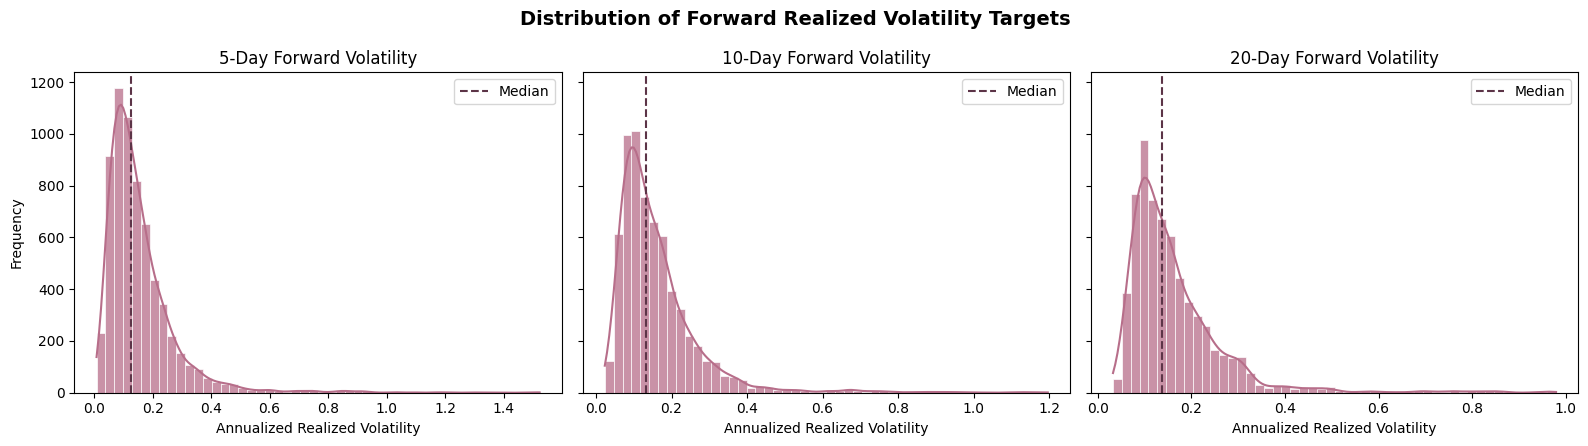

In [15]:
# --------------------------------------------------
# 3.4 Forward Volatility Distribution Visualization
# --------------------------------------------------

# Initialize figure and axes
fig_forward_rv_dist, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
    sharey=True
)

for ax, horizon in zip(axes, FORECAST_HORIZONS):

    target_col = f"Forward_RV_{horizon}D"

    sns.histplot(
        data=model_a_complete,
        x=target_col,
        bins=50,
        kde=True,
        ax=ax,
        color="#B76E8A",
        edgecolor="white",
        alpha=0.75
    )

    ax.axvline(
        model_a_complete[target_col].median(),
        color="#5C3447",
        linestyle="--",
        linewidth=1.5,
        label="Median"
    )

    ax.set_title(f"{horizon}-Day Forward Volatility")
    ax.set_xlabel("Annualized Realized Volatility")
    ax.set_ylabel("Frequency" if horizon == 5 else "")
    ax.legend()

fig_forward_rv_dist.suptitle(
    "Distribution of Forward Realized Volatility Targets",
    fontsize=14,
    fontweight="bold"
)

fig_forward_rv_dist.tight_layout()

plt.show()

**Key Observation:**

- **Average volatility:** Mean annualized realized volatility increases slightly from 0.1556 (5-day) to 0.1633 (20-day), while median volatility increases from 0.1249 to 0.1368.
- **Volatility dispersion:** The standard deviation decreases from 0.1225 at the 5-day horizon to 0.1066 at the 20-day horizon, indicating that longer forecasting windows produce relatively smoother volatility estimates.
- **Extreme observations:** Maximum annualized volatility decreases from 1.5229 (5-day) to 0.9790 (20-day), reflecting the greater sensitivity of shorter windows to concentrated market shocks.
- **Distribution asymmetry:** All three targets exhibit substantial positive skewness, ranging from 3.1157 to 3.4761.
- **Tail behavior:** High excess kurtosis values (14.9879–21.3091) indicate heavy-tailed distributions, particularly at shorter forecasting horizons.

### Section 3.5 - Summary of Target Engineering

The forward volatility target engineering process successfully established three supervised forecasting targets representing future S&P 500 realized volatility over 5, 10, and 20 trading days.

The completed activities include:

- **Target construction:** Calculated annualized forward realized volatility using subsequent daily S&P 500 log returns.
- **Numerical validation:** Independently verified target calculations across 15 observation-horizon combinations.
- **Temporal alignment:** Confirmed that targets reflect future returns without incorporating the forecast-date return.
- **Sample preparation:** Removed 20 observations with incomplete forecasting horizons, retaining 6,499 complete observations.
- **Distribution analysis:** Identified positively skewed, heavy-tailed volatility distributions, with greater dispersion and more extreme outcomes at shorter forecasting horizons.

The final target-engineered dataset contains **6,499 observations and 29 variables**, covering forecast origin dates from February 1, 2000, through December 2, 2025.

These targets will be used consistently across Ridge Regression, Support Vector Regression (SVR), and XGBoost to evaluate forecasting accuracy and the incremental predictive contribution of HMM-derived market regime probabilities.

## Section 4 - Supervised Modeling Dataset Preparation

This section prepares the supervised modeling dataset by defining the predictor specifications, forecasting targets, and chronological data partitions.

The preparation process includes:

- **Predictor selection:** Identifying historical market characteristics and filtered HMM regime probabilities used for forecasting.
- **Feature specifications:** Establishing market-only and regime-enhanced predictor sets.
- **Forecasting targets:** Defining the primary 5-day target and additional 10- and 20-day forecasting horizons.
- **Chronological partitioning:** Separating observations into training, validation, and testing periods.
- **Leakage prevention:** Applying a temporal purge to prevent overlapping forward-return windows from crossing partition boundaries.
- **Dataset verification:** Confirming the completeness, integrity, and temporal consistency of the resulting modeling partitions.

Both predictor specifications use identical observations, forecast horizons, and evaluation periods to support direct comparisons between Ridge Regression, Support Vector Regression (SVR), and XGBoost.

Feature standardization will be performed within the relevant model pipelines using training data only, preventing information leakage from validation or testing observations.

### Section 4.1 - Define Predictor Sets and Forecasting Targets

This subsection establishes two predictor specifications:

- **Market-only:** Eleven market indicators covering VIX, trailing realized volatility, skewness, and kurtosis.
- **Market + HMM:** The eleven market indicators supplemented by three filtered regime probabilities.

Both specifications are evaluated using Ridge Regression, SVR, and XGBoost to forecast realized volatility over 5, 10, and 20 trading days.

In [16]:
# --------------------------------------------------
# 4.1 Define Predictor Sets and Forecasting Targets
# --------------------------------------------------

# Market-only predictors
base_features = [
    "VIX_Level",
    "VIX_Change",
    "Realized_Vol_5D",
    "Realized_Vol_10D",
    "Realized_Vol_20D",
    "Return_Skew_5D",
    "Return_Skew_10D",
    "Return_Skew_20D",
    "Return_Kurt_5D",
    "Return_Kurt_10D",
    "Return_Kurt_20D"
]

# Filtered HMM probabilities
regime_predictors = [
    "Filtered_P_Calm",
    "Filtered_P_Transition",
    "Filtered_P_Stressed"
]

# Regime-enhanced predictor set
enhanced_features = base_features + regime_predictors

# Define model feature specifications
feature_sets = {
    "Market-only": base_features,
    "Market + HMM": enhanced_features
}

# Forecasting targets (defined in Section 3)
HORIZONS = tuple(FORECAST_HORIZONS)

targets = [
    f"Forward_RV_{h}D"
    for h in HORIZONS
]

PRIMARY_HORIZON = 5
primary_target = f"Forward_RV_{PRIMARY_HORIZON}D"

# Define supervised algorithms
SUPERVISED_MODELS = [
    "Ridge",
    "SVR",
    "XGBoost"
]

# Verify required variable availability
required_columns = list(dict.fromkeys(
    enhanced_features + targets
))

missing_columns = [
    col for col in required_columns
    if col not in model_a_complete.columns
]

assert not missing_columns, (
    f"Required variables missing: {missing_columns}"
)

assert model_a_complete[required_columns].notna().all().all(), (
    "Missing values detected in predictors or targets."
)

assert len(base_features) == 11
assert len(enhanced_features) == 14

# Display modeling configuration
configuration_summary = pd.DataFrame({
    "Component": [
        "Market-only predictors",
        "Regime-enhanced predictors",
        "Additional HMM predictors",
        "Primary forecasting horizon",
        "Additional forecasting horizons",
        "Supervised algorithms",
        "Eligible observations"
    ],
    "Configuration": [
        len(base_features),
        len(enhanced_features),
        len(regime_predictors),
        f"{PRIMARY_HORIZON} trading days",
        "10 and 20 trading days",
        ", ".join(SUPERVISED_MODELS),
        len(model_a_complete)
    ]
})

print("Supervised Modeling Configuration")
print("-" * 55)

display(configuration_summary)

print("\nMarket-only Predictors:")
display(pd.DataFrame({"Feature": base_features}))

print("\nHMM Regime Predictors:")
display(pd.DataFrame({"Feature": regime_predictors}))

print("\nForecasting Targets:")
display(pd.DataFrame({"Target": targets}))

Supervised Modeling Configuration
-------------------------------------------------------


,Component,Configuration
0,Market-only predictors,11
1,Regime-enhanced predictors,14
2,Additional HMM predictors,3
3,Primary forecasting horizon,5 trading days
4,Additional forecasting horizons,10 and 20 trading days
5,Supervised algorithms,"Ridge, SVR, XGBoost"
6,Eligible observations,6499



Market-only Predictors:


,Feature
0,VIX_Level
1,VIX_Change
2,Realized_Vol_5D
3,Realized_Vol_10D
4,Realized_Vol_20D
5,Return_Skew_5D
6,Return_Skew_10D
7,Return_Skew_20D
8,Return_Kurt_5D
9,Return_Kurt_10D



HMM Regime Predictors:


,Feature
0,Filtered_P_Calm
1,Filtered_P_Transition
2,Filtered_P_Stressed



Forecasting Targets:


,Target
0,Forward_RV_5D
1,Forward_RV_10D
2,Forward_RV_20D


**Key Observations:**

The supervised forecasting framework was configured using two feature specifications:

- **Market-only:** Eleven predictors covering VIX, trailing realized volatility, return skewness, and kurtosis.
- **Market + HMM:** Fourteen predictors, including three additional filtered regime probabilities.
- **Forecasting targets:** Forward realized volatility over 5, 10, and 20 trading days.
- **Model families:** Ridge Regression, Support Vector Regression (SVR), and XGBoost.
- **Modeling sample:** 6,499 complete observations.

Both feature specifications will be evaluated across identical forecasting horizons and chronological data partitions to ensure consistent model comparisons.

### Section 4.2 - Chronological Train, Validation, and Test Splits

The modeling sample is divided chronologically into three periods:

- **Training (2000–2018):** Model estimation and parameter learning.
- **Validation (2019–2021):** Hyperparameter selection and model comparison.
- **Testing (2022–2025):** Final out-of-sample forecasting evaluation.

Chronological partitioning preserves the temporal structure of financial data and prevents random mixing of historical and future observations.

Overlapping forward-return windows will be addressed through boundary purging in Section 4.3.

In [17]:
# --------------------------------------------------
# 4.2 Chronological Train, Validation, and Test Splits
# --------------------------------------------------

# Define chronological boundaries
TRAIN_END = pd.Timestamp("2018-12-31")
VAL_END = pd.Timestamp("2021-12-31")

# Assign observations to partitions
train_raw = model_a_complete.loc[
    model_a_complete["Date"] <= TRAIN_END
].copy()

val_raw = model_a_complete.loc[
    (model_a_complete["Date"] > TRAIN_END)
    & (model_a_complete["Date"] <= VAL_END)
].copy()

test_raw = model_a_complete.loc[
    model_a_complete["Date"] > VAL_END
].copy()

# Summarize partition dimensions and dates
split_summary = pd.DataFrame([
    {
        "Partition": name,
        "Observations": len(df),
        "Start Date": df["Date"].min().date(),
        "End Date": df["Date"].max().date()
    }
    for name, df in [
        ("Training", train_raw),
        ("Validation", val_raw),
        ("Testing", test_raw)
    ]
])

print("Chronological Partition Summary")
print("-" * 55)

display(split_summary)

# Verify partition completeness
assert (
    len(train_raw) + len(val_raw) + len(test_raw)
    == len(model_a_complete)
), "Partition counts do not match the modeling sample."

# Verify chronological separation
assert train_raw["Date"].max() < val_raw["Date"].min()
assert val_raw["Date"].max() < test_raw["Date"].min()

print("\nChronological partitions created successfully.")

Chronological Partition Summary
-------------------------------------------------------


,Partition,Observations,Start Date,End Date
0,Training,4759,2000-02-01,2018-12-31
1,Validation,757,2019-01-02,2021-12-31
2,Testing,983,2022-01-03,2025-12-02



Chronological partitions created successfully.


**Key Observations:**

The modeling dataset was successfully divided into three chronological partitions:

- **Training:** 4,759 observations from February 1, 2000, through December 31, 2018.
- **Validation:** 757 observations from January 2, 2019, through December 31, 2021.
- **Testing:** 983 observations from January 3, 2022, through December 2, 2025.

All 6,499 observations were retained, and the partitions contain non-overlapping, chronologically ordered forecast dates.

The next subsection applies a temporal purge to prevent forward volatility targets from overlapping subsequent evaluation periods.

### Section 4.3 - Purge Overlapping Forecast Windows

Forward realized volatility targets use returns from the subsequent 5, 10, or 20 trading days, creating potential overlap across chronological partitions.

To prevent target leakage, the final 20 observations are excluded from both the training and validation partitions.

The testing partition remains unchanged, preserving the full out-of-sample evaluation period. This approach establishes consistent temporal separation across all forecasting horizons.

In [18]:
# --------------------------------------------------
# 4.3 Purge Overlapping Forecast Windows
# --------------------------------------------------

# Maximum forecasting horizon
PURGE_WINDOW = max(FORECAST_HORIZONS)

# Remove final 20 observations at partition boundaries
train_df = train_raw.iloc[:-PURGE_WINDOW].copy()
val_df = val_raw.iloc[:-PURGE_WINDOW].copy()
test_df = test_raw.copy()

# Summarize purged partitions
purge_summary = pd.DataFrame([
    {
        "Partition": name,
        "Original": len(original),
        "Purged": len(original) - len(purged),
        "Retained": len(purged),
        "Start Date": purged["Date"].min().date(),
        "End Date": purged["Date"].max().date()
    }
    for name, original, purged in [
        ("Training", train_raw, train_df),
        ("Validation", val_raw, val_df),
        ("Testing", test_raw, test_df)
    ]
])

print("Purged Chronological Partition Summary")
print("-" * 55)

display(purge_summary)

# Verify expected purge counts
assert len(train_df) == len(train_raw) - PURGE_WINDOW
assert len(val_df) == len(val_raw) - PURGE_WINDOW
assert len(test_df) == len(test_raw)

# Verify chronological separation
assert train_df["Date"].max() < val_df["Date"].min()
assert val_df["Date"].max() < test_df["Date"].min()

# Verify no target window crosses the next partition boundary
full_dates = pd.DatetimeIndex(model_a_targets["Date"])

for earlier, later in [
    (train_df, val_raw),
    (val_df, test_raw)
]:
    last_origin = earlier["Date"].max()
    next_start = later["Date"].min()

    origin_position = full_dates.get_loc(last_origin)
    target_end = full_dates[origin_position + PURGE_WINDOW]

    assert target_end < next_start, (
        f"Forward target window crosses boundary at {next_start}"
    )

print("\nTemporal purge validated successfully.")

Purged Chronological Partition Summary
-------------------------------------------------------


,Partition,Original,Purged,Retained,Start Date,End Date
0,Training,4759,20,4739,2000-02-01,2018-11-29
1,Validation,757,20,737,2019-01-02,2021-12-02
2,Testing,983,0,983,2022-01-03,2025-12-02



Temporal purge validated successfully.


**Key Observations:**

The purge validation confirmed that forward target windows do not cross into subsequent partitions, reducing the risk of target leakage during model development and evaluation.

### Section 4.4 - Verify Modeling Partitions

This subsection validates the final training, validation, and testing datasets.

The assessment verifies predictor and target completeness, chronological separation, observation uniqueness, and consistent sample sizes across forecasting specifications.

These checks establish the final modeling partitions for Ridge Regression, SVR, and XGBoost.

In [19]:
# --------------------------------------------------
# 4.4 Verify Modeling Partitions
# --------------------------------------------------

partitions = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

partition_results = []

# Validate each modeling partition
for name, df in partitions.items():

    required = enhanced_features + targets

    partition_results.append({
        "Partition": name,
        "Observations": len(df),
        "Missing Predictors": int(
            df[enhanced_features].isna().sum().sum()
        ),
        "Missing Targets": int(
            df[targets].isna().sum().sum()
        ),
        "Duplicate Dates": int(
            df["Date"].duplicated().sum()
        ),
        "Chronologically Sorted": df["Date"].is_monotonic_increasing,
        "Finite Numerical Values": bool(
            np.isfinite(df[required].to_numpy()).all()
        )
    })

# Display verification summary
partition_verification = pd.DataFrame(partition_results)

print("Modeling Partition Verification Summary")
print("-" * 55)

display(partition_verification)

# Validate completeness and integrity
assert (
    partition_verification["Missing Predictors"] == 0
).all()

assert (
    partition_verification["Missing Targets"] == 0
).all()

assert (
    partition_verification["Duplicate Dates"] == 0
).all()

assert partition_verification[
    "Chronologically Sorted"
].all()

assert partition_verification[
    "Finite Numerical Values"
].all()

# Verify chronological separation
assert train_df["Date"].max() < val_df["Date"].min()
assert val_df["Date"].max() < test_df["Date"].min()

# Verify total retained observations
assert sum(len(df) for df in partitions.values()) == 6459

print("\nModeling partitions verified successfully.")

Modeling Partition Verification Summary
-------------------------------------------------------


,Partition,Observations,Missing Predictors,Missing Targets,Duplicate Dates,Chronologically Sorted,Finite Numerical Values
0,Training,4739,0,0,0,True,True
1,Validation,737,0,0,0,True,True
2,Testing,983,0,0,0,True,True



Modeling partitions verified successfully.


**Key Observations:**

The verified partitions provide a consistent dataset for supervised model development and evaluation.


### Section 4.5 - Summary of Modeling Dataset Preparation

The supervised modeling dataset was successfully prepared and validated.

- **Feature specifications:** Defined 11 market-only predictors and 14 regime-enhanced predictors.
- **Forecasting targets:** Established forward realized volatility over 5, 10, and 20 trading days.
- **Chronological splitting:** Separated observations into training (2000–2018), validation (2019–2021), and testing (2022–2025).
- **Leakage prevention:** Applied a 20-trading-day purge at the training and validation boundaries.
- **Final sample:** Retained 6,459 observations across the three partitions, with no missing values or duplicate dates.

Feature scaling will be fitted within the relevant training pipelines to prevent validation and test information from influencing preprocessing.

The resulting partitions will be used consistently across Ridge Regression, Support Vector Regression (SVR), and XGBoost.

## Section 5 - Persistence Benchmark

This section establishes a naive persistence benchmark for forecasting S&P 500 realized volatility over 5, 10, and 20 trading days.

The benchmark assumes that future realized volatility equals the most recently observed trailing volatility over the corresponding horizon.

Performance is evaluated using Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE), providing a reference for assessing the predictive value of the supervised learning models.

### Section 5.1 - Define the Persistence Benchmark

The persistence benchmark uses trailing realized volatility as a direct forecast of future volatility:

- **5-day forecast:** `Realized_Vol_5D` predicts `Forward_RV_5D`.
- **10-day forecast:** `Realized_Vol_10D` predicts `Forward_RV_10D`.
- **20-day forecast:** `Realized_Vol_20D` predicts `Forward_RV_20D`.

The benchmark requires no training or hyperparameter optimization and is evaluated on the same chronological partitions as the supervised models.

In [20]:
# --------------------------------------------------
# 5.1 Define the Persistence Benchmark
# --------------------------------------------------

# Map forecasting targets to their persistence predictors
persistence_features = {
    5: "Realized_Vol_5D",
    10: "Realized_Vol_10D",
    20: "Realized_Vol_20D"
}

# Define evaluation partitions
evaluation_partitions = {
    "Validation": val_df,
    "Testing": test_df
}

# Verify persistence features are available
for horizon, feature in persistence_features.items():

    target = f"Forward_RV_{horizon}D"

    for name, df in evaluation_partitions.items():
        assert feature in df.columns
        assert target in df.columns
        assert df[[feature, target]].notna().all().all()

print("Persistence Benchmark Configuration")
print("-" * 55)

display(pd.DataFrame({
    "Horizon": list(persistence_features.keys()),
    "Persistence Predictor": list(persistence_features.values()),
    "Forecast Target": [
        f"Forward_RV_{h}D"
        for h in persistence_features
    ]
}))

print("\nPersistence benchmark configuration verified.")

Persistence Benchmark Configuration
-------------------------------------------------------


,Horizon,Persistence Predictor,Forecast Target
0,5,Realized_Vol_5D,Forward_RV_5D
1,10,Realized_Vol_10D,Forward_RV_10D
2,20,Realized_Vol_20D,Forward_RV_20D



Persistence benchmark configuration verified.


### Section 5.2 - Generate Benchmark Forecasts

Persistence forecasts are generated directly from the corresponding trailing realized volatility features.

Forecasts are produced for the validation and testing partitions across all three horizons. Predictions are retained for subsequent model comparisons and statistical evaluation.

In [21]:
# --------------------------------------------------
# 5.2 Generate Benchmark Forecasts
# --------------------------------------------------

# Store benchmark predictions by partition and horizon
persistence_predictions = {}

for partition_name, df in evaluation_partitions.items():

    persistence_predictions[partition_name] = {}

    for horizon, feature in persistence_features.items():

        target = f"Forward_RV_{horizon}D"

        # Actual future volatility
        y_true = df[target].to_numpy()

        # Persistence forecast
        y_pred = df[feature].to_numpy()

        persistence_predictions[partition_name][horizon] = {
            "Date": df["Date"].to_numpy(),
            "Actual": y_true,
            "Predicted": y_pred
        }

# Preview five-day testing forecasts
preview = persistence_predictions["Testing"][5]

persistence_preview = pd.DataFrame({
    "Date": preview["Date"],
    "Actual": preview["Actual"],
    "Persistence Forecast": preview["Predicted"]
})

print("Persistence Forecast Preview - 5-Day Testing")
print("-" * 55)

display(persistence_preview.head(10))

Persistence Forecast Preview - 5-Day Testing
-------------------------------------------------------


,Date,Actual,Persistence Forecast
0,2022-01-03,0.1282,0.0610
1,2022-01-04,0.1644,0.0605
2,2022-01-05,0.0812,0.1515
3,2022-01-06,0.1381,0.1529
4,2022-01-07,0.1370,0.1528
5,2022-01-10,0.1880,0.1282
6,2022-01-11,0.1483,0.1644
7,2022-01-12,0.1147,0.0812
8,2022-01-13,0.1286,0.1381
9,2022-01-14,0.1406,0.1370


### Section 5.3 - Evaluate Benchmark Performance

Persistence forecasting accuracy is evaluated using:

- **RMSE:** Penalizes larger forecasting errors more heavily.
- **MAE:** Measures the average absolute forecasting error.

Both metrics are calculated for the validation and testing periods. Lower values indicate better forecasting performance.

In [22]:
# --------------------------------------------------
# 5.3 Evaluate Benchmark Performance
# --------------------------------------------------

benchmark_results = []

for partition_name, horizon_data in persistence_predictions.items():

    for horizon, predictions in horizon_data.items():

        y_true = predictions["Actual"]
        y_pred = predictions["Predicted"]

        # Calculate forecasting errors
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        mae = mean_absolute_error(y_true, y_pred)

        benchmark_results.append({
            "Model": "Persistence",
            "Partition": partition_name,
            "Horizon": horizon,
            "RMSE": rmse,
            "MAE": mae
        })

# Consolidate performance results
benchmark_results_df = pd.DataFrame(benchmark_results)

print("Persistence Benchmark Performance")
print("-" * 55)

display(
    benchmark_results_df.sort_values(
        ["Partition", "Horizon"]
    ).reset_index(drop=True)
)

Persistence Benchmark Performance
-------------------------------------------------------


,Model,Partition,Horizon,RMSE,MAE
0,Persistence,Testing,5,0.0974,0.0647
1,Persistence,Testing,10,0.0849,0.0543
2,Persistence,Testing,20,0.0761,0.0487
3,Persistence,Validation,5,0.1256,0.0794
4,Persistence,Validation,10,0.1312,0.0807
5,Persistence,Validation,20,0.1580,0.0914


### Section 5.4 - Summary of Persistence Benchmark

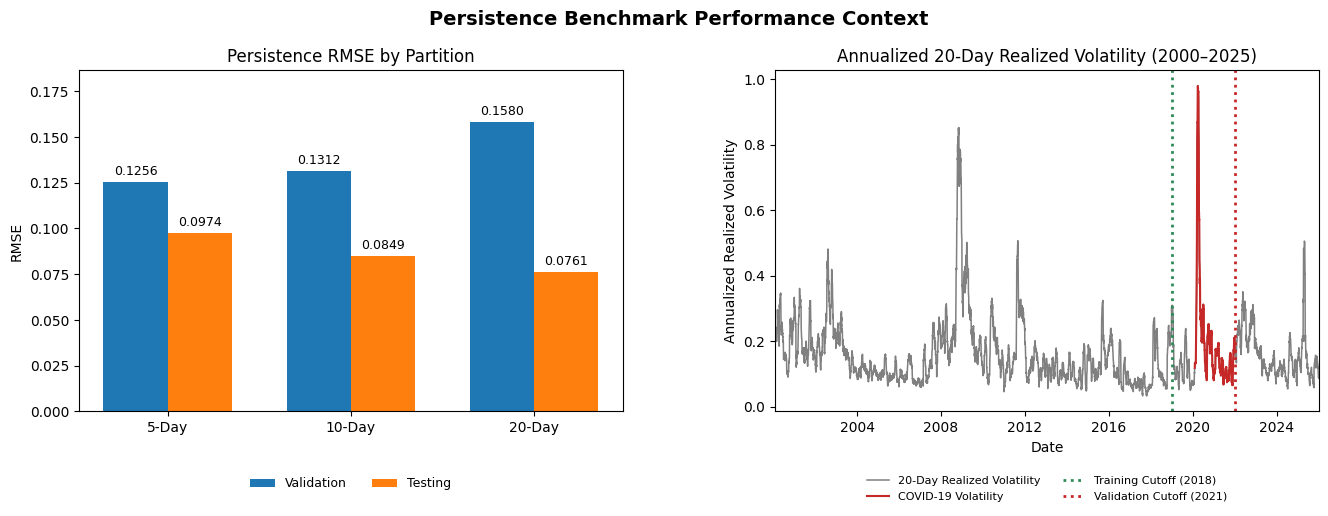

In [32]:
# --------------------------------------------------
# 5.4 Persistence Benchmark Context Visualization
# --------------------------------------------------

# Prepare RMSE comparison
rmse_plot_df = (
    benchmark_results_df
    .pivot(index="Horizon", columns="Partition", values="RMSE")
    .sort_index()
)

# Full historical 20-day realized volatility
rv_20_full_df = model_a_df[
    ["Date", "Realized_Vol_20D"]
].copy()

# Define important dates
train_cutoff = pd.Timestamp("2018-12-31")
val_cutoff = pd.Timestamp("2021-12-31")

covid_start = pd.Timestamp("2020-02-01")
covid_end = pd.Timestamp("2021-12-31")

# Initialize figure
fig_persistence_context, axes = plt.subplots(
    1, 2,
    figsize=(16, 5.5)
)

# ----------------------------------------
# Panel A: Persistence RMSE Comparison
# ----------------------------------------

x = np.arange(len(rmse_plot_df.index))
width = 0.35

# Validation bars - original blue
bars_val = axes[0].bar(
    x - width / 2,
    rmse_plot_df["Validation"],
    width=width,
    color="#1f77b4",
    label="Validation"
)

# Testing bars - original orange
bars_test = axes[0].bar(
    x + width / 2,
    rmse_plot_df["Testing"],
    width=width,
    color="#ff7f0e",
    label="Testing"
)

# Add RMSE labels above bars
for bars in [bars_val, bars_test]:
    axes[0].bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{h}-Day" for h in rmse_plot_df.index])

axes[0].set_ylim(
    0,
    rmse_plot_df.to_numpy().max() * 1.18
)

axes[0].set_title("Persistence RMSE by Partition")
axes[0].set_ylabel("RMSE")

# Horizontal legend below graph
axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    frameon=False,
    fontsize=9
)

# ----------------------------------------
# Panel B: Historical 20-Day Realized Volatility
# ----------------------------------------

# Plot full realized volatility series in gray
axes[1].plot(
    rv_20_full_df["Date"],
    rv_20_full_df["Realized_Vol_20D"],
    color="#808080",
    linewidth=1.1,
    label="20-Day Realized Volatility",
    zorder=2
)

# Highlight COVID-19 realized volatility in red
covid_mask = (
    (rv_20_full_df["Date"] >= covid_start) &
    (rv_20_full_df["Date"] <= covid_end)
)

axes[1].plot(
    rv_20_full_df.loc[covid_mask, "Date"],
    rv_20_full_df.loc[covid_mask, "Realized_Vol_20D"],
    color="#C62828",
    linewidth=1.5,
    label="COVID-19 Volatility",
    zorder=3
)

# Training cutoff - green dotted line
axes[1].axvline(
    train_cutoff,
    color="#2E8B57",
    linestyle=":",
    linewidth=2,
    label="Training Cutoff (2018)"
)

# Validation cutoff - red dotted line
axes[1].axvline(
    val_cutoff,
    color="#C62828",
    linestyle=":",
    linewidth=2,
    label="Validation Cutoff (2021)"
)

axes[1].set_title("Annualized 20-Day Realized Volatility (2000–2025)")
axes[1].set_ylabel("Annualized Realized Volatility")
axes[1].set_xlabel("Date")

axes[1].set_xlim(
    rv_20_full_df["Date"].min(),
    rv_20_full_df["Date"].max()
)

# Horizontal legend below graph
axes[1].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=2,
    frameon=False,
    fontsize=8
)

# ----------------------------------------
# Final Figure Formatting
# ----------------------------------------

fig_persistence_context.suptitle(
    "Persistence Benchmark Performance Context",
    fontsize=14,
    fontweight="bold"
)

fig_persistence_context.subplots_adjust(
    bottom=0.25,
    top=0.87,
    wspace=0.28
)

plt.show()

**Key Observations:**

The persistence benchmark was evaluated across three forecasting horizons, with results contextualized against historical market volatility.

- **Testing performance:** RMSE decreased from 0.0974 (5-day) to 0.0761 (20-day), with lower forecasting errors at longer horizons.
- **Validation versus testing:** Validation RMSE exceeded testing RMSE across all horizons, with the largest difference at the 20-day horizon (0.1580 versus 0.0761).
- **Market conditions:** The historical volatility series highlights the sharp increase in volatility during COVID-19, which occurred within the validation period and may have contributed to its higher forecasting errors.
- **Forecasting limitations:** Persistence relies on trailing volatility and cannot anticipate abrupt changes in market conditions, potentially underestimating volatility spikes and overestimating subsequent declines.

Overall, the benchmark demonstrates the limitations of relying exclusively on historical volatility, particularly during periods of rapid market adjustment. These results establish a reference for evaluating whether Ridge Regression, SVR, and XGBoost provide more accurate and adaptive forecasts.

## 9. Persistence Baseline : Primary and Robustness Horizons

A persistence baseline is established to evaluate whether supervised learning models can improve volatility forecasting beyond a simple historical benchmark.

The persistence approach assumes that future realized volatility over a given forecasting horizon will equal the realized volatility observed over the preceding period of the same length. Accordingly, trailing 5-, 10-, and 20-day realized volatility are used to predict their corresponding forward volatility targets.

The primary analysis evaluates the 5-day forecasting horizon, while the 10- and 20-day horizons serve as robustness checks.

Forecasting performance is evaluated using Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE). The resulting baseline establishes a reference for assessing the predictive performance of Ridge Regression and XGBoost, with and without HMM regime information.

### 9.1 Evaluating Persistence Baseline

In [ ]:
# Evaluation function
def scores(actual, pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(actual, pred))),
        "MAE": float(mean_absolute_error(actual, pred))
    }

# Store model results and predictions
results_records = []
forecast_records = []

# Evaluate persistence across all horizons
for h in HORIZONS:

    target_col = f"Forward_RV_{h}D"
    baseline_col = f"Realized_Vol_{h}D"

    for sample_name, sample_df in [
        ("Validation", validation_df),
        ("Test", test_df)
    ]:

        actual = sample_df[target_col].to_numpy()
        predicted = sample_df[baseline_col].to_numpy()

        metrics = scores(actual, predicted)

        results_records.append({
            "Model": "Persistence",
            "Features": "Matched trailing volatility",
            "Horizon": h,
            "Sample": sample_name,
            **metrics
        })

        forecast_records.append(pd.DataFrame({
            "Date": sample_df["Date"].to_numpy(),
            "Actual": actual,
            "Predicted": predicted,
            "Model": "Persistence",
            "Features": "Matched trailing volatility",
            "Horizon": h,
            "Sample": sample_name
        }))

# Consolidate results
results = pd.DataFrame(results_records)

forecasts = pd.concat(
    forecast_records,
    ignore_index=True
)

# Display baseline performance
baseline_results = results.sort_values(
    ["Horizon", "Sample"]
)
display(
    baseline_results.style.format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}"
    })
)

,Model,Features,Horizon,Sample,RMSE,MAE
1,Persistence,Matched trailing volatility,5,Test,0.0974,0.0647
0,Persistence,Matched trailing volatility,5,Validation,0.1256,0.0794
3,Persistence,Matched trailing volatility,10,Test,0.0849,0.0543
2,Persistence,Matched trailing volatility,10,Validation,0.1312,0.0807
5,Persistence,Matched trailing volatility,20,Test,0.0761,0.0487
4,Persistence,Matched trailing volatility,20,Validation,0.1580,0.0914


### Observation : Interpretation Presestance Forecasting Performance Metrics

Forecasting performance is evaluated using two error metrics:

- **Root Mean Squared Error (RMSE):** Measures the magnitude of forecasting errors, assigning greater weight to larger deviations between predicted and actual volatility. Lower RMSE values indicate better forecasting accuracy, particularly in reducing large prediction errors.

- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual volatility. Lower MAE values indicate smaller average forecasting errors and provide a more direct interpretation of typical prediction accuracy.

Both metrics are expressed in the same units as the forecasting targets: **annualized realized volatility in decimal form**.

For example, the primary 5-day persistence baseline produces:

- **RMSE = 0.0975:** Equivalent to 9.75 annualized volatility percentage points. This metric emphasizes larger forecasting errors and should not be interpreted as the average absolute error.
- **MAE = 0.0646:** Equivalent to 6.46 annualized volatility percentage points. On average, the persistence forecast differs from actual forward 5-day annualized volatility by 6.46 percentage points.

These values represent absolute forecasting errors in annualized volatility, rather than percentage errors relative to actual volatility. For example, an MAE of 0.0646 does not mean that forecasts are inaccurate by 6.46% in relative terms.

Lower RMSE and MAE indicate better forecasting performance. However, comparisons should be made between models predicting the same forecasting horizon and evaluated over the same sample period.

## 10. Ridge Regression : Market-Only vs. Regime-Enhanced Forecasting

Ridge Regression is implemented as an interpretable, regularized linear forecasting model to evaluate whether historical market characteristics can predict future realized volatility more accurately than the persistence baseline.

Two model specifications are evaluated. The market-only specification uses the 11 engineered market predictors, while the regime-enhanced specification additionally incorporates the filtered probabilities of the Calm, Transition, and Stressed regimes generated by Model B.

Ridge Regression applies L2 regularization to reduce coefficient instability arising from correlated predictors. Predictor variables are standardized using parameters estimated exclusively from the training data.

The regularization parameter is selected using validation period RMSE, and the final models are evaluated on the independent test period. The primary analysis focuses on 5-day forward realized volatility, with 10- and 20-day forecasts serving as robustness checks.

### 10.1 Training and Valitation of Ridge Regression

In [ ]:
# Candidate regularization strengths
alpha_grid = [0.01, 0.1, 1, 10, 100, 1000]

ridge_models = {}
ridge_tuning_records = []

feature_sets = {
    "Market-only": base_features,
    "Market + HMM": enhanced_features
}

for h in HORIZONS:
    target_col = f"Forward_RV_{h}D"

    y_train = train_df[target_col]
    y_val = validation_df[target_col]

    for feature_name, feature_cols in feature_sets.items():
        X_train = train_df[feature_cols]
        X_val = validation_df[feature_cols]

        for alpha in alpha_grid:
            pipeline = Pipeline([
                ("scaler", StandardScaler()),
                ("ridge", Ridge(alpha=alpha))
            ])

            pipeline.fit(X_train, y_train)
            val_pred = pipeline.predict(X_val)

            metrics = scores(y_val, val_pred)

            ridge_tuning_records.append({
                "Horizon": h,
                "Features": feature_name,
                "Alpha": alpha,
                "Validation_RMSE": metrics["RMSE"],
                "Validation_MAE": metrics["MAE"]
            })

# Consolidate tuning results
ridge_tuning = pd.DataFrame(ridge_tuning_records)

# Select best alpha for each horizon and feature set
best_ridge = (
    ridge_tuning
    .sort_values(
        ["Validation_RMSE", "Alpha"]
    )
    .groupby(["Horizon", "Features"], as_index=False)
    .first()
    .sort_values(["Horizon", "Features"])
)

display(best_ridge)


,Horizon,Features,Alpha,Validation_RMSE,Validation_MAE
0,5,Market + HMM,0.0100,0.1134,0.0697
1,5,Market-only,10.0000,0.1139,0.0699
2,10,Market + HMM,0.0100,0.1113,0.0672
3,10,Market-only,0.0100,0.1114,0.0672
4,20,Market + HMM,0.0100,0.1249,0.0683
5,20,Market-only,0.0100,0.1245,0.0686


Visualization - Ridge Hyperparameter Selection

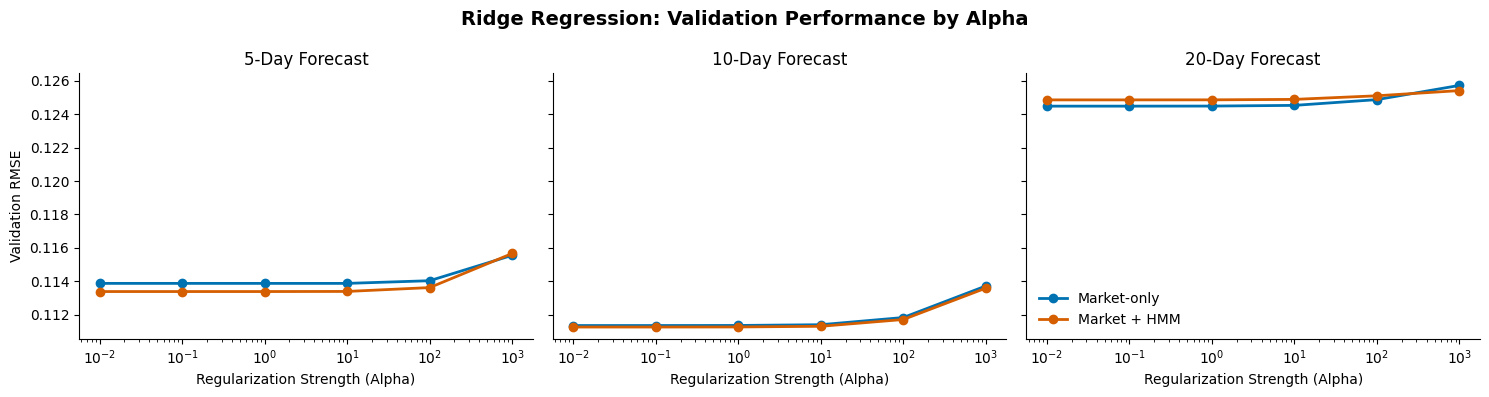

In [ ]:

fig_ridge_tuning, axes = plt.subplots(
    1, 3,
    figsize=(15, 4),
    sharey=True
)

ridge_colors = {
    "Market-only": "#0072B2",
    "Market + HMM": "#D55E00"
}

for ax, h in zip(axes, HORIZONS):
    subset = ridge_tuning[
        ridge_tuning["Horizon"] == h
    ]

    for feature_name in feature_sets:
        data = subset[
            subset["Features"] == feature_name
        ].sort_values("Alpha")

        ax.plot(
            data["Alpha"],
            data["Validation_RMSE"],
            marker="o",
            linewidth=2,
            color=ridge_colors[feature_name],
            label=feature_name
        )

    ax.set_xscale("log")
    ax.set_title(f"{h}-Day Forecast")
    ax.set_xlabel("Regularization Strength (Alpha)")
    ax.grid(False)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Validation RMSE")
axes[-1].legend(frameon=False)

fig_ridge_tuning.suptitle(
    "Ridge Regression: Validation Performance by Alpha",
    fontsize=14,
    fontweight="bold"
)

fig_ridge_tuning.tight_layout()
plt.show()


### Observation : Ridge Regression Hyperparameter Selection

- **Primary Forecasting Horizon:** The regime-enhanced Ridge model achieved a validation RMSE of 0.1134, compared with 0.1139 for the market-only model, representing a modest improvement of approximately 0.44%.

- **Horizon Sensitivity:** Incorporating HMM regime probabilities produced a marginal improvement at the 10-day horizon, while the market-only model achieved slightly lower RMSE at the 20-day horizon. This suggests that the incremental predictive contribution of regime information varies across forecasting horizons.

- **Regularization Sensitivity:** Validation RMSE remained relatively stable across most candidate regularization strengths. The selected alpha was 0.01 for five of the six configurations, while the 5-day market-only model selected alpha = 10.

- **Baseline Comparison:** Ridge Regression improved validation RMSE relative to the persistence baseline across all three horizons, with approximate improvements ranging from 9.7% to 21.2%. These findings provide preliminary evidence that market characteristics offer predictive value beyond historical volatility persistence.

- **Modeling Implications:** Although the regime-enhanced specification shows a small improvement at the primary forecasting horizon, its incremental value remains uncertain. Final conclusions will depend on performance in the independent test period.

### 10.2 Final Ridge Regression Evaluation

Following validation based hyperparameter selection, the six Ridge Regression configurations are evaluated on the independent 2022–2025 test dataset.

For each forecasting horizon, the market-only and regime-enhanced models are fitted using the training observations and their previously selected regularization parameters. Predictor standardization is estimated exclusively from the training data.

Out-of-sample performance is assessed using RMSE and MAE, with additional comparisons against the persistence baseline. The evaluation focuses primarily on the 5-day forecasting horizon, while the 10- and 20-day results assess robustness across longer forecasting periods.

This analysis determines whether incorporating HMM regime probabilities provides incremental forecasting improvements beyond the original market predictors.

In [ ]:
# NOTE: run this cell once, re-running it without resetting would cause duplicate entries for "results" & "forecasts" df's
# Fit selected Ridge models and evaluate test performance

ridge_models = {}
ridge_result_records = []
ridge_forecast_records = []

for _, config in best_ridge.iterrows():

    h = int(config["Horizon"])
    feature_name = config["Features"]
    alpha = float(config["Alpha"])

    feature_cols = feature_sets[feature_name]
    target_col = f"Forward_RV_{h}D"

    # Training observations
    X_train = train_df[feature_cols]
    y_train = train_df[target_col]

    # Test observations
    X_test = test_df[feature_cols]
    y_test = test_df[target_col]

    # Build and fit the selected pipeline
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))
    ])

    pipeline.fit(X_train, y_train)

    # Generate out-of-sample forecasts
    test_pred = pipeline.predict(X_test)

    # Calculate test performance
    metrics = scores(y_test, test_pred)

    ridge_models[(h, feature_name)] = pipeline

    ridge_result_records.append({
        "Model": "Ridge",
        "Features": feature_name,
        "Horizon": h,
        "Sample": "Test",
        **metrics
    })

    ridge_forecast_records.append(pd.DataFrame({
        "Date": test_df["Date"].to_numpy(),
        "Actual": y_test.to_numpy(),
        "Predicted": test_pred,
        "Model": "Ridge",
        "Features": feature_name,
        "Horizon": h,
        "Sample": "Test"
    }))

# Append Ridge results to the existing persistence results
results = pd.concat([
    results,
    pd.DataFrame(ridge_result_records)
], ignore_index=True)

forecasts = pd.concat([
    forecasts,
    *ridge_forecast_records
], ignore_index=True)

# Display test results
ridge_test_results = (
    results[
        (results["Model"] == "Ridge") &
        (results["Sample"] == "Test")
    ]
    .sort_values(["Horizon", "Features"])
)

display(
    ridge_test_results.style.format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}"
    })
)


,Model,Features,Horizon,Sample,RMSE,MAE
6,Ridge,Market + HMM,5,Test,0.0740,0.0494
7,Ridge,Market-only,5,Test,0.0738,0.0492
8,Ridge,Market + HMM,10,Test,0.0673,0.0428
9,Ridge,Market-only,10,Test,0.0670,0.0427
10,Ridge,Market + HMM,20,Test,0.0611,0.0393
11,Ridge,Market-only,20,Test,0.0607,0.0392


### 10.3 Copare Ridge Regression Against Persistence

In [ ]:

# Select test-period results
test_results = results[
    results["Sample"] == "Test"
].copy()

# Retrieve persistence benchmark by horizon
baseline = (
    test_results[test_results["Model"] == "Persistence"]
    .set_index("Horizon")[["RMSE", "MAE"]]
)

# Select Ridge results
ridge_comparison = test_results[
    test_results["Model"] == "Ridge"
].copy()

# Calculate percentage improvements
for metric in ["RMSE", "MAE"]:
    ridge_comparison[f"{metric}_Improvement_%"] = (
        1 - ridge_comparison[metric] /
        ridge_comparison["Horizon"].map(baseline[metric])
    ) * 100

display(
    ridge_comparison[
        ["Horizon", "Features", "RMSE", "MAE",
         "RMSE_Improvement_%", "MAE_Improvement_%"]
    ].sort_values(["Horizon", "Features"]).style.format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}",
        "RMSE_Improvement_%": "{:+.2f}%",
        "MAE_Improvement_%": "{:+.2f}%"
    })
)


,Horizon,Features,RMSE,MAE,RMSE_Improvement_%,MAE_Improvement_%
6,5,Market + HMM,0.0740,0.0494,+24.05%,+23.62%
7,5,Market-only,0.0738,0.0492,+24.23%,+24.01%
8,10,Market + HMM,0.0673,0.0428,+20.67%,+21.07%
9,10,Market-only,0.0670,0.0427,+21.11%,+21.28%
10,20,Market + HMM,0.0611,0.0393,+19.69%,+19.32%
11,20,Market-only,0.0607,0.0392,+20.22%,+19.65%


Visualization - Actual vs. Predicted 5-Day Volatility

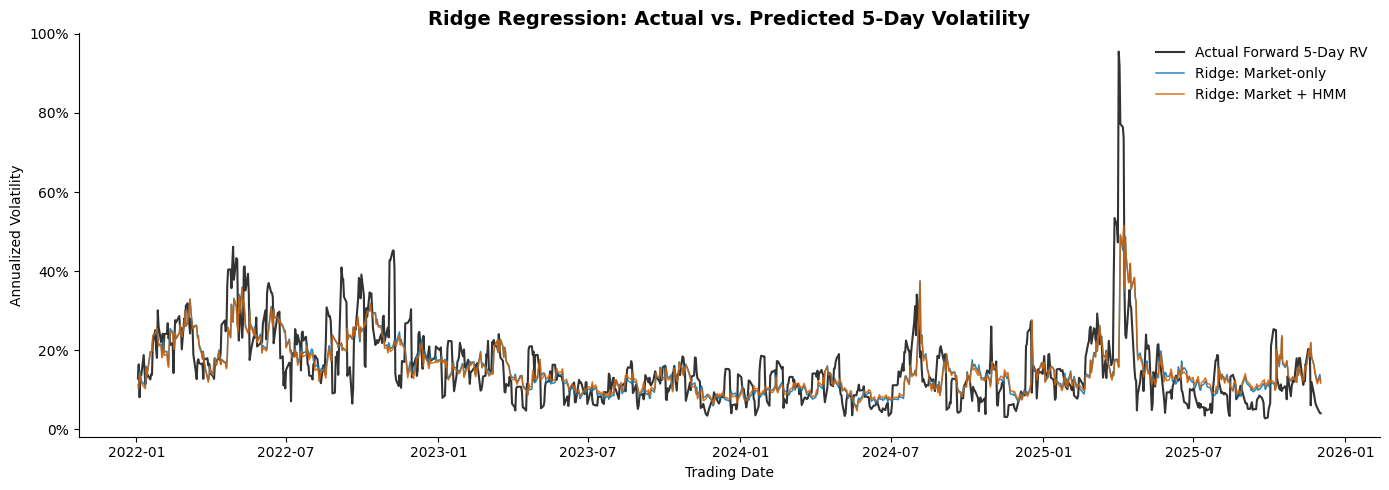

In [ ]:

# Primary 5-day Ridge predictions
ridge_plot = forecasts[
    (forecasts["Model"] == "Ridge") &
    (forecasts["Horizon"] == 5) &
    (forecasts["Sample"] == "Test")
]

ridge_wide = ridge_plot.pivot(
    index="Date",
    columns="Features",
    values="Predicted"
).sort_index()

actual_5d = test_df.set_index("Date")[
    "Forward_RV_5D"
].reindex(ridge_wide.index)

# Create and store figure
fig_ridge_5d_predictions, ax = plt.subplots(
    figsize=(14, 5)
)

ax.plot(
    actual_5d.index,
    actual_5d,
    label="Actual Forward 5-Day RV",
    color="#333333",
    linewidth=1.5
)

ax.plot(
    ridge_wide.index,
    ridge_wide["Market-only"],
    label="Ridge: Market-only",
    color="#0072B2",
    linewidth=1.1,
    alpha=0.85
)

ax.plot(
    ridge_wide.index,
    ridge_wide["Market + HMM"],
    label="Ridge: Market + HMM",
    color="#D55E00",
    linewidth=1.1,
    alpha=0.85
)

ax.set_title(
    "Ridge Regression: Actual vs. Predicted 5-Day Volatility",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Trading Date")
ax.set_ylabel("Annualized Volatility")
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=1.0)
)

ax.legend(frameon=False)
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

fig_ridge_5d_predictions.tight_layout()
plt.show()


Visualization - Incremental Contribution of HMM Information

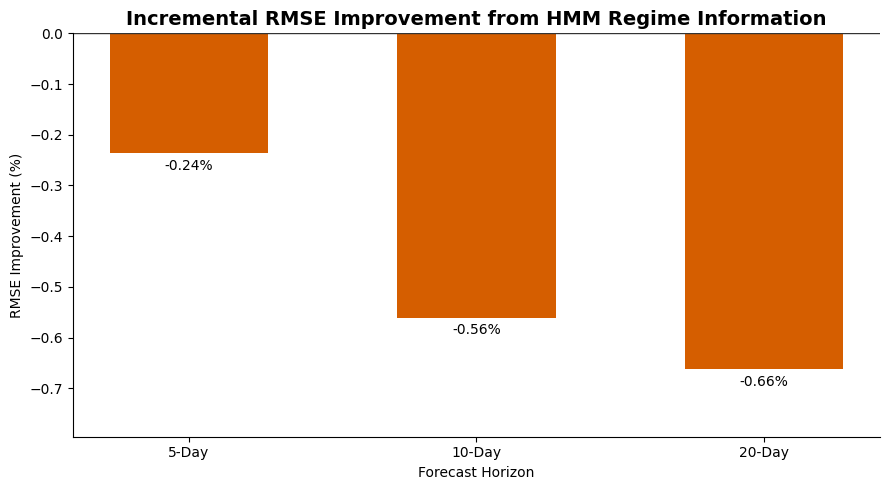

In [ ]:

# Compare market-only against regime-enhanced Ridge
ridge_rmse = ridge_test_results.pivot(
    index="Horizon",
    columns="Features",
    values="RMSE"
)

hmm_improvement = (
    1 - ridge_rmse["Market + HMM"] /
    ridge_rmse["Market-only"]
) * 100

fig_ridge_hmm_improvement, ax = plt.subplots(
    figsize=(9, 5)
)

bar_colors = [
    "#0072B2" if value >= 0 else "#D55E00"
    for value in hmm_improvement
]

bars = ax.bar(
    [f"{h}-Day" for h in hmm_improvement.index],
    hmm_improvement.values,
    color=bar_colors,
    width=0.55
)

ax.axhline(0, color="#333333", linewidth=1)

ax.bar_label(
    bars,
    fmt="%+.2f%%",
    padding=4
)

ax.set_title(
    "Incremental RMSE Improvement from HMM Regime Information",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Forecast Horizon")
ax.set_ylabel("RMSE Improvement (%)")

ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=0.2)

fig_ridge_hmm_improvement.tight_layout()
plt.show()

Visualization - Actual Vs. Predicted 5-Day Volatility

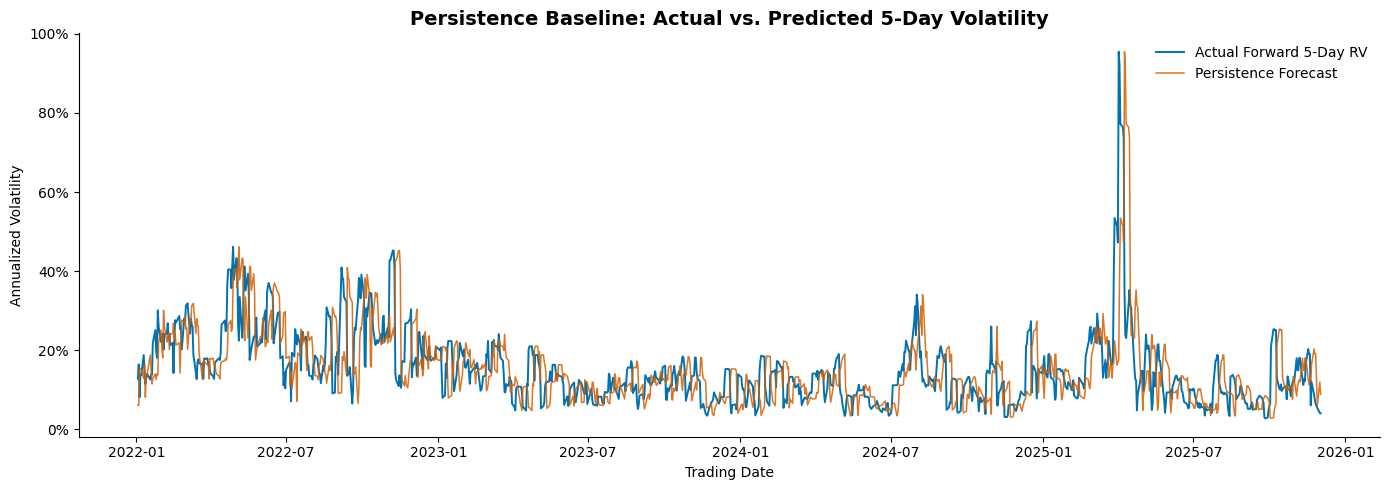

In [ ]:
# Actual vs. Predicted 5-Day Volatility
baseline_5d = forecasts[
    (forecasts["Model"] == "Persistence") &
    (forecasts["Horizon"] == 5) &
    (forecasts["Sample"] == "Test")
].sort_values("Date")

fig_persistence_5d, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    baseline_5d["Date"],
    baseline_5d["Actual"],
    label="Actual Forward 5-Day RV",
    color="#0072B2",
    linewidth=1.4
)

ax.plot(
    baseline_5d["Date"],
    baseline_5d["Predicted"],
    label="Persistence Forecast",
    color="#D55E00",
    linewidth=1.1,
    alpha=0.85
)

ax.set_title(
    "Persistence Baseline: Actual vs. Predicted 5-Day Volatility",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Trading Date")
ax.set_ylabel("Annualized Volatility")
ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=1.0)
)
ax.legend(frameon=False)
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

fig_persistence_5d.tight_layout()
plt.show()


Visualization - Test Period Forecast Errors

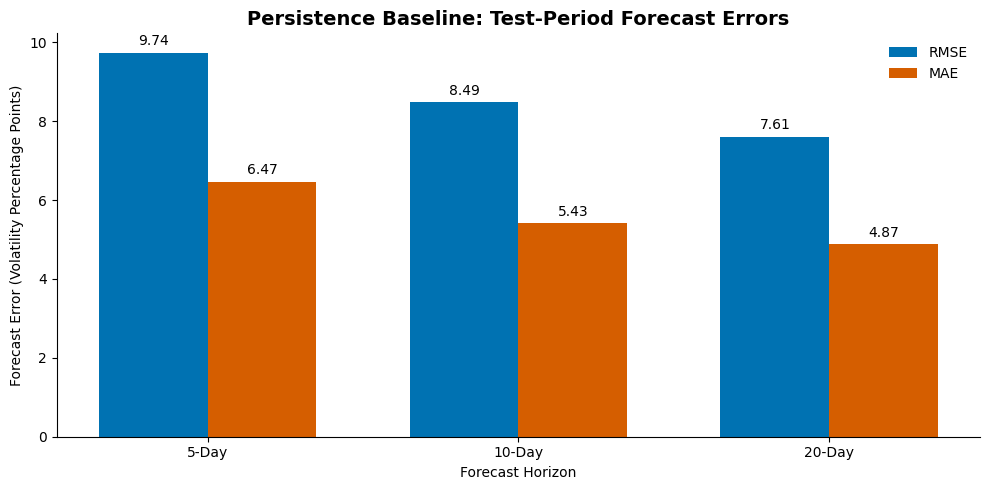

In [ ]:
#  Test-Period Forecast Errors
baseline_test = results[
    (results["Model"] == "Persistence") &
    (results["Sample"] == "Test")
].sort_values("Horizon")

x = np.arange(len(baseline_test))
width = 0.35

fig_persistence_errors, ax = plt.subplots(
    figsize=(10, 5)
)

bars_rmse = ax.bar(
    x - width / 2,
    baseline_test["RMSE"] * 100,
    width,
    label="RMSE",
    color="#0072B2"
)

bars_mae = ax.bar(
    x + width / 2,
    baseline_test["MAE"] * 100,
    width,
    label="MAE",
    color="#D55E00"
)

ax.bar_label(bars_rmse, fmt="%.2f", padding=3)
ax.bar_label(bars_mae, fmt="%.2f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{h}-Day" for h in baseline_test["Horizon"]]
)

ax.set_title(
    "Persistence Baseline: Test-Period Forecast Errors",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Forecast Horizon")
ax.set_ylabel("Forecast Error (Volatility Percentage Points)")
ax.legend(frameon=False)
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

fig_persistence_errors.tight_layout()
plt.show()


### Observation : Ridge Regression Test Performance

- **Primary Forecasting Performance:** The market-only Ridge model achieved a test RMSE of 0.0738 and MAE of 0.0490 for the 5-day forecast, improving upon the persistence baseline by 24.30% and 24.18%, respectively.

- **Incremental HMM Contribution:** Adding HMM regime probabilities resulted in marginal RMSE deterioration of 0.28%, 0.61%, and 0.70% for the 5-, 10-, and 20-day forecasts, respectively. This suggests that regime information provides limited incremental predictive value within the Ridge Regression specification.

- **Volatility Tracking:** Both Ridge models generally captured broad changes in realized volatility but underestimated extreme volatility spikes, particularly during the sharp market disruption observed in 2025.

- **Horizon Robustness:** Ridge Regression consistently outperformed the persistence baseline across all three horizons, with market-only RMSE improvements ranging from 20.27% to 24.30%. However, the additional HMM predictors did not improve forecasting accuracy at any horizon.

- **Modeling Implications:** Historical market characteristics offer substantial predictive improvements over persistence, while the inclusion of HMM regime probabilities provides no additional benefit within the tested linear specification. The subsequent XGBoost analysis will investigate whether nonlinear relationships and interactions can extract further predictive value from regime information.

## 11. XGBoost Regression : Market-Only vs. Regime-Enhanced Forecasting

XGBoost Regression is implemented as a nonlinear supervised learning approach to investigate whether complex relationships and interactions among market characteristics and HMM regime probabilities improve forward realized volatility forecasting.

Two model specifications are evaluated: a **market-only model** using the 11 engineered market predictors and a **regime-enhanced model** incorporating the three filtered HMM probabilities generated by Model B.

Unlike Ridge Regression, XGBoost uses an ensemble of sequentially boosted decision trees to capture nonlinear relationships and feature interactions. This allows us to investigate whether the inferred market regimes provide predictive information that may not be captured by a regularized linear model.

To balance model complexity and predictive performance, a **controlled hyperparameter search** is conducted across the number of boosting trees, maximum tree depth, and learning rate. Row and feature subsampling rates are held constant. Candidate configurations are fitted on the training dataset and evaluated using validation RMSE, with the best-performing configuration selected separately for each forecasting horizon and predictor set.

The selected models are subsequently evaluated on the independent test dataset using RMSE and MAE. The primary analysis focuses on **5-day forward realized volatility**, while 10- and 20-day forecasts serve as robustness checks.

Finally, XGBoost performance is compared against the persistence baseline and Ridge Regression to determine whether nonlinear modeling improves forecasting accuracy and whether HMM regime information provides additional predictive value across forecasting horizons.

### 11.1 Hyperparameter Exploration Framework

To identify suitable XGBoost configurations, a controlled hyperparameter search is performed to examine how ensemble size, tree complexity, and learning rate influence volatility forecasting performance.

The following parameters are explored:

| Hyperparameter | Values Explored | Purpose |
|---|---|---|
| **Number of Trees (`n_estimators`)** | 150, 250, 400 | Examines whether increasing the number of boosting trees improves forecasting accuracy. |
| **Maximum Tree Depth (`max_depth`)** | 2, 3, 4 | Evaluates how tree complexity and the ability to capture nonlinear feature interactions affect performance. |
| **Learning Rate (`learning_rate`)** | 0.03, 0.05 | Examines whether smaller boosting updates improve generalization. |
| **Row Subsampling (`subsample`)** | 0.85 (fixed) | Uses 85% of training observations per boosting iteration to help control overfitting. |
| **Feature Subsampling (`colsample_bytree`)** | 0.90 (fixed) | Samples 90% of predictors per tree to reduce dependence on individual features. |

The search evaluates **18 hyperparameter combinations** for each predictor specification and forecasting horizon, resulting in **108 model configurations** across the three horizons and two predictor sets.

Each configuration is trained using the training dataset and evaluated using validation RMSE. The configuration with the lowest validation RMSE is selected for each forecasting horizon and predictor set, with simpler configurations preferred in the event of a tie.

The selected models are subsequently evaluated on the independent test dataset to assess forecasting accuracy and the incremental contribution of HMM regime information.

### 11.2 XGBoost Hyperparameter Search Implementation
A grid search is performed across the predefined hyperparameter combinations for both the market-only and regime-enhanced XGBoost specifications.

Each configuration is fitted using training-period observations and evaluated against the validation dataset using RMSE and MAE. The search is repeated for the primary 5-day forecasting horizon and the 10- and 20-day robustness horizons.

The results are stored for subsequent hyperparameter selection and sensitivity analysis. The independent test dataset remains excluded from this procedure.

In [ ]:
# Define hyperparameter search space
xgb_param_grid = {
    "n_estimators": [150, 250, 400],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.05]
}

# Define predictor specifications
xgb_feature_sets = {
    "Market-only": base_features,
    "Market + HMM": enhanced_features
}

# Initialize results storage
xgb_tuning_records = []

# Evaluate candidate configurations
for h in HORIZONS:

    target_col = f"Forward_RV_{h}D"

    for feature_name, feature_cols in xgb_feature_sets.items():

        X_train = train_df[feature_cols]
        y_train = train_df[target_col]

        X_val = validation_df[feature_cols]
        y_val = validation_df[target_col]

        for n_estimators, max_depth, learning_rate in product(
            xgb_param_grid["n_estimators"],
            xgb_param_grid["max_depth"],
            xgb_param_grid["learning_rate"]
        ):

            model = XGBRegressor(
                n_estimators=n_estimators,
                max_depth=max_depth,
                learning_rate=learning_rate,
                subsample=0.85,
                colsample_bytree=0.90,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=2
            )

            model.fit(X_train, y_train)

            val_pred = model.predict(X_val)
            metrics = scores(y_val, val_pred)

            xgb_tuning_records.append({
                "Horizon": h,
                "Features": feature_name,
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "learning_rate": learning_rate,
                "Validation_RMSE": metrics["RMSE"],
                "Validation_MAE": metrics["MAE"]
            })

# Consolidate results
xgb_tuning = pd.DataFrame(xgb_tuning_records)

print("Total configurations evaluated:", len(xgb_tuning))
print("\nConfigurations by horizon and predictor set:")

display(
    xgb_tuning.groupby(
        ["Horizon", "Features"]
    ).size().rename("Configurations")
)

display(xgb_tuning.head())

Total configurations evaluated: 108

Configurations by horizon and predictor set:


Horizon  Features    
5        Market + HMM    18
         Market-only     18
10       Market + HMM    18
         Market-only     18
20       Market + HMM    18
         Market-only     18
Name: Configurations, dtype: int64

,Horizon,Features,n_estimators,max_depth,learning_rate,Validation_RMSE,Validation_MAE
0,5,Market-only,150,2,0.0300,0.1122,0.0702
1,5,Market-only,150,2,0.0500,0.1115,0.0709
2,5,Market-only,150,3,0.0300,0.1149,0.0733
3,5,Market-only,150,3,0.0500,0.1159,0.0745
4,5,Market-only,150,4,0.0300,0.1182,0.0755


### 11.3 Optimal Hyperparameter Selection

Following the hyperparameter search, the configuration achieving the lowest validation RMSE is selected separately for each forecasting horizon and predictor specification.

This procedure identifies the preferred combination of boosting trees, maximum tree depth, and learning rate within the predefined search space.

The selected configurations are subsequently examined to determine whether model complexity and preferred hyperparameters differ between the market-only and regime-enhanced specifications. Final forecasting performance will be assessed using the independent test dataset.

In [ ]:

# Select configuration with lowest validation RMSE
best_xgb = (
    xgb_tuning
    .sort_values([
        "Validation_RMSE",
        "max_depth",
        "n_estimators",
        "learning_rate"
    ])
    .groupby(
        ["Horizon", "Features"],
        as_index=False
    )
    .first()
    .sort_values(["Horizon", "Features"])
    .reset_index(drop=True)
)

# Display selected configurations
display(
    best_xgb.style.format({
        "learning_rate": "{:.2f}",
        "Validation_RMSE": "{:.4f}",
        "Validation_MAE": "{:.4f}"
    })
)


,Horizon,Features,n_estimators,max_depth,learning_rate,Validation_RMSE,Validation_MAE
0,5,Market + HMM,150,2,0.05,0.1108,0.0703
1,5,Market-only,150,2,0.05,0.1115,0.0709
2,10,Market + HMM,400,2,0.03,0.1097,0.0674
3,10,Market-only,150,2,0.05,0.1093,0.0671
4,20,Market + HMM,400,2,0.05,0.1241,0.0684
5,20,Market-only,400,2,0.03,0.1248,0.0683


Visualization - XGBoost Hyperparameter Sensitivity Visualization

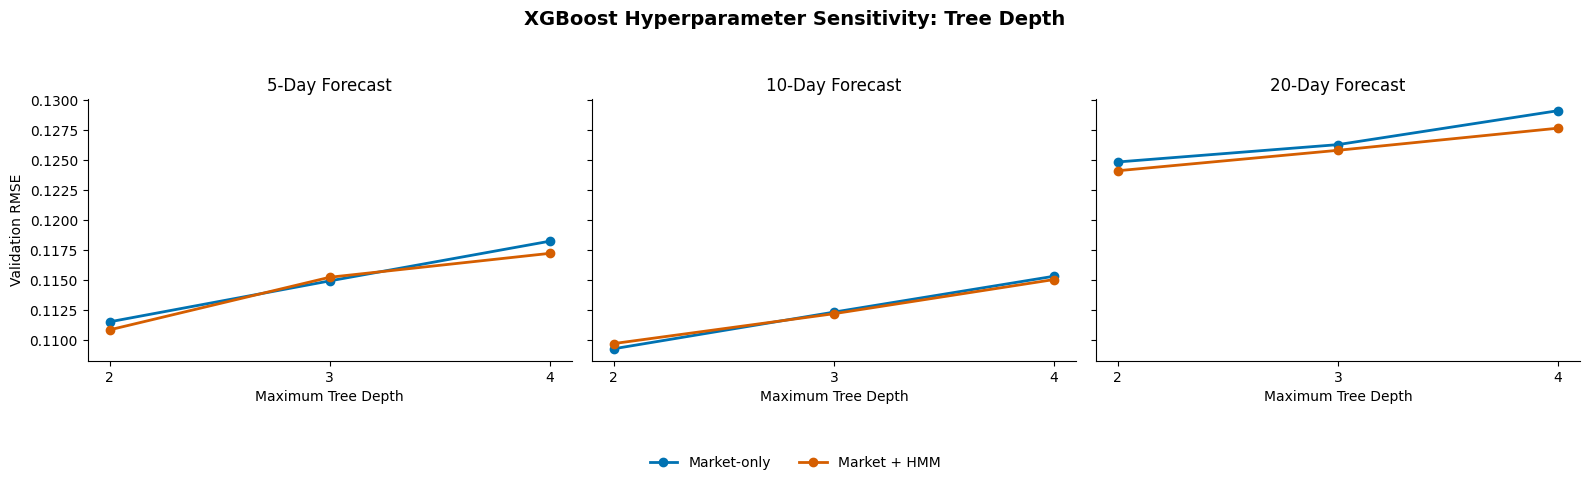

In [ ]:

# color palette
model_colors = {
    "Market-only": "#0072B2",
    "Market + HMM": "#D55E00"
}

# Create and store figure
fig_xgb_tuning, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.5),
    sharey=True
)

for ax, h in zip(axes, HORIZONS):

    subset = xgb_tuning[
        xgb_tuning["Horizon"] == h
    ]

    # Minimum validation RMSE at each depth
    plot_data = (
        subset.groupby(
            ["max_depth", "Features"],
            as_index=False
        )["Validation_RMSE"]
        .min()
    )

    for feature_name, color in model_colors.items():

        data = plot_data[
            plot_data["Features"] == feature_name
        ].sort_values("max_depth")

        ax.plot(
            data["max_depth"],
            data["Validation_RMSE"],
            color=color,
            marker="o",
            linewidth=2,
            label=feature_name
        )

    ax.set_title(f"{h}-Day Forecast")
    ax.set_xlabel("Maximum Tree Depth")
    ax.set_xticks([2, 3, 4])
    ax.grid(False)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Validation RMSE")

handles, labels = axes[0].get_legend_handles_labels()

fig_xgb_tuning.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=2,
    frameon=False
)

fig_xgb_tuning.suptitle(
    "XGBoost Hyperparameter Sensitivity: Tree Depth",
    fontsize=14,
    fontweight="bold"
)

fig_xgb_tuning.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()



Visualization - Incremental RMSE Improvement from HMM Regime Information (Validation)

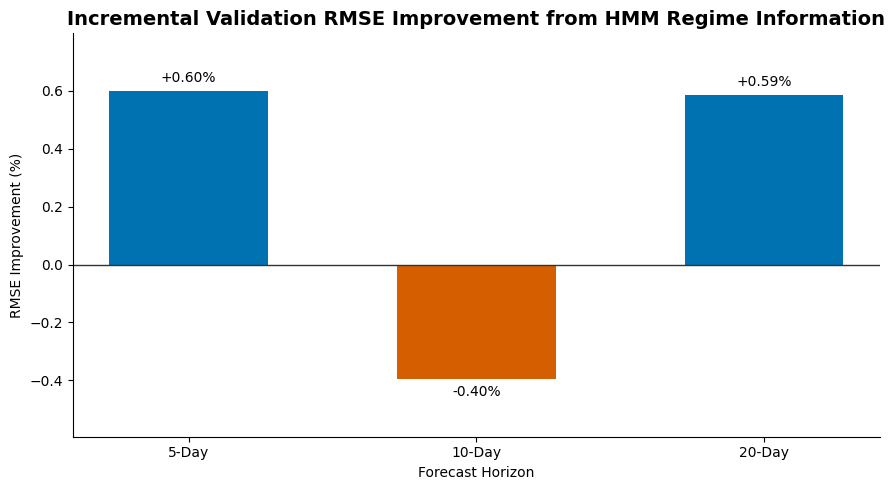

In [ ]:
# Pivot validation RMSE results
xgb_rmse_compare = best_xgb.pivot(
    index="Horizon",
    columns="Features",
    values="Validation_RMSE"
)

# Calculate incremental improvement from adding HMM
xgb_hmm_improvement = (
    1 - xgb_rmse_compare["Market + HMM"] /
    xgb_rmse_compare["Market-only"]
) * 100

# Create and store figure
fig_xgb_hmm_improvement, ax = plt.subplots(
    figsize=(9, 5)
)

# Blue if HMM helped, red-orange if it worsened performance
bar_colors = [
    "#0072B2" if value >= 0 else "#D55E00"
    for value in xgb_hmm_improvement
]

bars = ax.bar(
    [f"{h}-Day" for h in xgb_hmm_improvement.index],
    xgb_hmm_improvement.values,
    color=bar_colors,
    width=0.55
)

ax.axhline(0, color="#333333", linewidth=1)

ax.bar_label(
    bars,
    fmt="%+.2f%%",
    padding=4
)

ax.set_title(
    "Incremental Validation RMSE Improvement from HMM Regime Information",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Forecast Horizon")
ax.set_ylabel("RMSE Improvement (%)")

ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=0.2)

fig_xgb_hmm_improvement.tight_layout()
plt.show()

### Observation : Incremental HMM Contribution to XGBoots Performance

- **Primary Forecasting Horizon:** Incorporating HMM regime probabilities reduced XGBoost validation RMSE by 0.60% for the 5-day forecast, indicating a modest improvement over the market-only specification.

- **Horizon Sensitivity:** The contribution of regime information varied across forecasting horizons, with a 0.40% deterioration at the 10-day horizon and a 0.59% improvement at the 20-day horizon.

- **Predictive Contribution:** Although XGBoost allows for nonlinear relationships and feature interactions, the incremental improvements from incorporating HMM probabilities remained below 1% across all horizons. This suggests that the additional regime information provides limited benefits during validation.

- **Modeling Implications:** The mixed results indicate that the predictive contribution of HMM regime information is not consistent across forecasting horizons. Independent test-period evaluation is required to determine whether these modest improvements generalize beyond the validation sample.

### 11.4 Final XGBoost Test Evaluation

Following validation-based hyperparameter selection, the six preferred XGBoost configurations are evaluated on the independent 2022–2025 test dataset.

Each configuration is fitted using the original training observations and its selected hyperparameters, without incorporating validation or test observations into model estimation. Forecasts are generated for the three horizons using the market-only and regime-enhanced predictor sets.

Out of sample forecasting performance is evaluated using RMSE and MAE. Results are compared against the persistence baseline and Ridge Regression to assess the benefits of nonlinear modeling.

Particular attention is given to the incremental RMSE improvement from incorporating HMM regime probabilities, determining whether the modest validation improvements translate into better independent test performance.

We'll evaluate three comparisons:
1. XGBoost vs. persistence: Does nonlinear modeling improve upon historical volatility persistence?
2. XGBoost vs. Ridge Regression: Does nonlinear modeling outperform our regularized linear benchmark?
3. Market-only vs. Market + HMM: Does regime information provide incremental predictive value?

### 11.4 Fit Selected XGBoost Models and Evaluate Test Preformance

In [ ]:

# Fit selected XGBoost models and evaluate test performance

xgb_models = {}
xgb_result_records = []
xgb_forecast_records = []

for _, config in best_xgb.iterrows():

    h = int(config["Horizon"])
    feature_name = config["Features"]

    feature_cols = xgb_feature_sets[feature_name]
    target_col = f"Forward_RV_{h}D"

    # Selected hyperparameters
    params = {
        "n_estimators": int(config["n_estimators"]),
        "max_depth": int(config["max_depth"]),
        "learning_rate": float(config["learning_rate"]),
        "subsample": 0.85,
        "colsample_bytree": 0.90,
        "objective": "reg:squarederror",
        "random_state": 42,
        "n_jobs": 2
    }

    # Training observations
    X_train = train_df[feature_cols]
    y_train = train_df[target_col]

    # Independent test observations
    X_test = test_df[feature_cols]
    y_test = test_df[target_col]

    # Fit selected XGBoost configuration
    model = XGBRegressor(**params)
    model.fit(X_train, y_train)

    # Generate test predictions
    test_pred = model.predict(X_test)

    # Calculate forecasting errors
    metrics = scores(y_test, test_pred)

    # Store fitted model
    xgb_models[(h, feature_name)] = model

    # Store test performance
    xgb_result_records.append({
        "Model": "XGBoost",
        "Features": feature_name,
        "Horizon": h,
        "Sample": "Test",
        **metrics
    })

    # Store individual forecasts
    xgb_forecast_records.append(pd.DataFrame({
        "Date": test_df["Date"].to_numpy(),
        "Actual": y_test.to_numpy(),
        "Predicted": test_pred,
        "Model": "XGBoost",
        "Features": feature_name,
        "Horizon": h,
        "Sample": "Test"
    }))

# Consolidate XGBoost results
xgb_test_results = pd.DataFrame(xgb_result_records)

xgb_test_forecasts = pd.concat(
    xgb_forecast_records,
    ignore_index=True
)

# Replace existing XGBoost entries if cell is rerun
results = pd.concat([
    results[results["Model"] != "XGBoost"],
    xgb_test_results
], ignore_index=True)

forecasts = pd.concat([
    forecasts[forecasts["Model"] != "XGBoost"],
    xgb_test_forecasts
], ignore_index=True)

# Display XGBoost test performance
display(
    xgb_test_results
    .sort_values(["Horizon", "Features"])
    .style.format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}"
    })
)

,Model,Features,Horizon,Sample,RMSE,MAE
0,XGBoost,Market + HMM,5,Test,0.0769,0.0504
1,XGBoost,Market-only,5,Test,0.0756,0.0497
2,XGBoost,Market + HMM,10,Test,0.0711,0.0430
3,XGBoost,Market-only,10,Test,0.0698,0.0427
4,XGBoost,Market + HMM,20,Test,0.0646,0.0396
5,XGBoost,Market-only,20,Test,0.0631,0.0388


### 11.4 Compare XGBoost with Persistence and Ridge Regression

In [ ]:

# Extract independent test results
test_results = results[
    results["Sample"] == "Test"
].copy()

# Prepare benchmark RMSE values
persistence_rmse = (
    test_results[test_results["Model"] == "Persistence"]
    .set_index("Horizon")["RMSE"]
)

ridge_rmse = (
    test_results[
        (test_results["Model"] == "Ridge") &
        (test_results["Features"] == "Market-only")
    ]
    .set_index("Horizon")["RMSE"]
)

# Create comparison table
xgb_comparison = xgb_test_results.copy()

# Improvement relative to persistence
xgb_comparison["Vs_Persistence_%"] = (
    1 - xgb_comparison["RMSE"] /
    xgb_comparison["Horizon"].map(persistence_rmse)
) * 100

# Improvement relative to market-only Ridge
xgb_comparison["Vs_Ridge_%"] = (
    1 - xgb_comparison["RMSE"] /
    xgb_comparison["Horizon"].map(ridge_rmse)
) * 100

display(
    xgb_comparison[
        ["Horizon", "Features", "RMSE", "MAE",
         "Vs_Persistence_%", "Vs_Ridge_%"]
    ]
    .sort_values(["Horizon", "Features"])
    .style.format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}",
        "Vs_Persistence_%": "{:+.2f}%",
        "Vs_Ridge_%": "{:+.2f}%"
    })
)


,Horizon,Features,RMSE,MAE,Vs_Persistence_%,Vs_Ridge_%
0,5,Market + HMM,0.0769,0.0504,+21.03%,-4.22%
1,5,Market-only,0.0756,0.0497,+22.41%,-2.40%
2,10,Market + HMM,0.0711,0.0430,+16.26%,-6.15%
3,10,Market-only,0.0698,0.0427,+17.78%,-4.22%
4,20,Market + HMM,0.0646,0.0396,+15.19%,-6.30%
5,20,Market-only,0.0631,0.0388,+17.14%,-3.87%


### 11.4 Incremental HMM Contribution

In [ ]:

# Compare XGBoost specifications by horizon
xgb_rmse_test = xgb_test_results.pivot(
    index="Horizon",
    columns="Features",
    values="RMSE"
)

# Incremental improvement from HMM information
xgb_hmm_test_improvement = (
    1 - xgb_rmse_test["Market + HMM"] /
    xgb_rmse_test["Market-only"]
) * 100

hmm_test_summary = pd.DataFrame({
    "Market-only RMSE": xgb_rmse_test["Market-only"],
    "Market + HMM RMSE": xgb_rmse_test["Market + HMM"],
    "Incremental Improvement (%)": xgb_hmm_test_improvement
})

display(
    hmm_test_summary.style.format({
        "Market-only RMSE": "{:.4f}",
        "Market + HMM RMSE": "{:.4f}",
        "Incremental Improvement (%)": "{:+.2f}%"
    })
)

,Market-only RMSE,Market + HMM RMSE,Incremental Improvement (%)
Horizon,,,
5,0.0756,0.0769,-1.78%
10,0.0698,0.0711,-1.86%
20,0.0631,0.0646,-2.35%


Visualization - Actual Vs. Predicted 5-Day Volatility

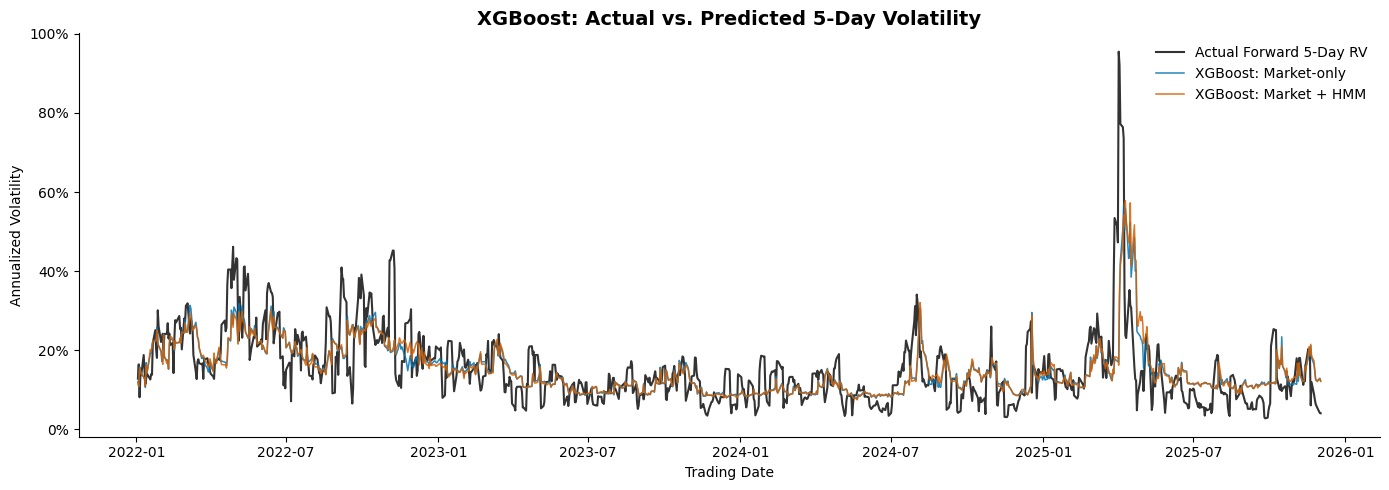

In [ ]:
# Select primary 5-day test forecasts
xgb_plot = forecasts[
    (forecasts["Model"] == "XGBoost") &
    (forecasts["Horizon"] == 5) &
    (forecasts["Sample"] == "Test")
]

# Reshape predictions for comparison
xgb_wide = xgb_plot.pivot(
    index="Date",
    columns="Features",
    values="Predicted"
).sort_index()

# Actual forward volatility
actual_5d = test_df.set_index("Date")[
    "Forward_RV_5D"
].reindex(xgb_wide.index)

# Create and store figure
fig_xgb_5d_predictions, ax = plt.subplots(
    figsize=(14, 5)
)

ax.plot(
    actual_5d.index,
    actual_5d,
    label="Actual Forward 5-Day RV",
    color="#333333",
    linewidth=1.5
)

ax.plot(
    xgb_wide.index,
    xgb_wide["Market-only"],
    label="XGBoost: Market-only",
    color="#0072B2",
    linewidth=1.1,
    alpha=0.85
)

ax.plot(
    xgb_wide.index,
    xgb_wide["Market + HMM"],
    label="XGBoost: Market + HMM",
    color="#D55E00",
    linewidth=1.1,
    alpha=0.85
)

ax.set_title(
    "XGBoost: Actual vs. Predicted 5-Day Volatility",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Trading Date")
ax.set_ylabel("Annualized Volatility")

ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=1.0)
)

ax.legend(frameon=False)
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

fig_xgb_5d_predictions.tight_layout()
plt.show()

Visualization - Incremental Test RMSE Improvement from HMM Information

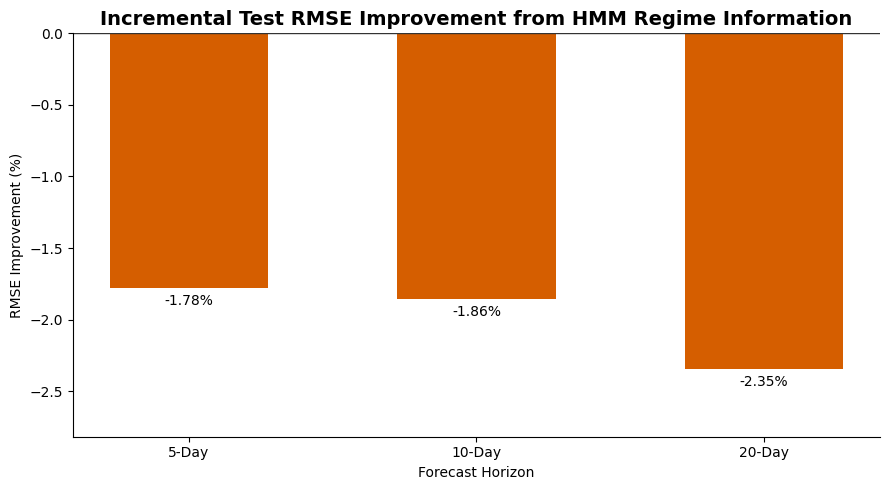

In [ ]:
# Incremental test RMSE improvement from HMM probabilities
xgb_hmm_test_improvement = (
    1 - xgb_rmse_test["Market + HMM"] /
    xgb_rmse_test["Market-only"]
) * 100

# Create and store figure
fig_xgb_hmm_test_improvement, ax = plt.subplots(
    figsize=(9, 5)
)

bar_colors = [
    "#0072B2" if value >= 0 else "#D55E00"
    for value in xgb_hmm_test_improvement
]

bars = ax.bar(
    [f"{h}-Day" for h in xgb_hmm_test_improvement.index],
    xgb_hmm_test_improvement.values,
    color=bar_colors,
    width=0.55
)

ax.axhline(0, color="#333333", linewidth=1)

ax.bar_label(
    bars,
    fmt="%+.2f%%",
    padding=4
)

ax.set_title(
    "Incremental Test RMSE Improvement from HMM Regime Information",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Forecast Horizon")
ax.set_ylabel("RMSE Improvement (%)")

ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=0.2)

fig_xgb_hmm_test_improvement.tight_layout()
plt.show()


Visualization - XGBoost Feature Importance

Feature importance is examined for the regime-enhanced XGBoost model at the primary 5-day forecasting horizon to investigate the relative contribution of market characteristics and HMM regime probabilities.

Importance is measured using XGBoost's gain-based metric, which reflects the average reduction in the training objective achieved when a feature is used to split a decision tree.

The analysis examines whether regime probabilities contribute meaningfully to the fitted model relative to observable market predictors. Feature importance describes how the model uses its predictors but does not establish causal effects or independent improvements in out-of-sample forecasting accuracy.

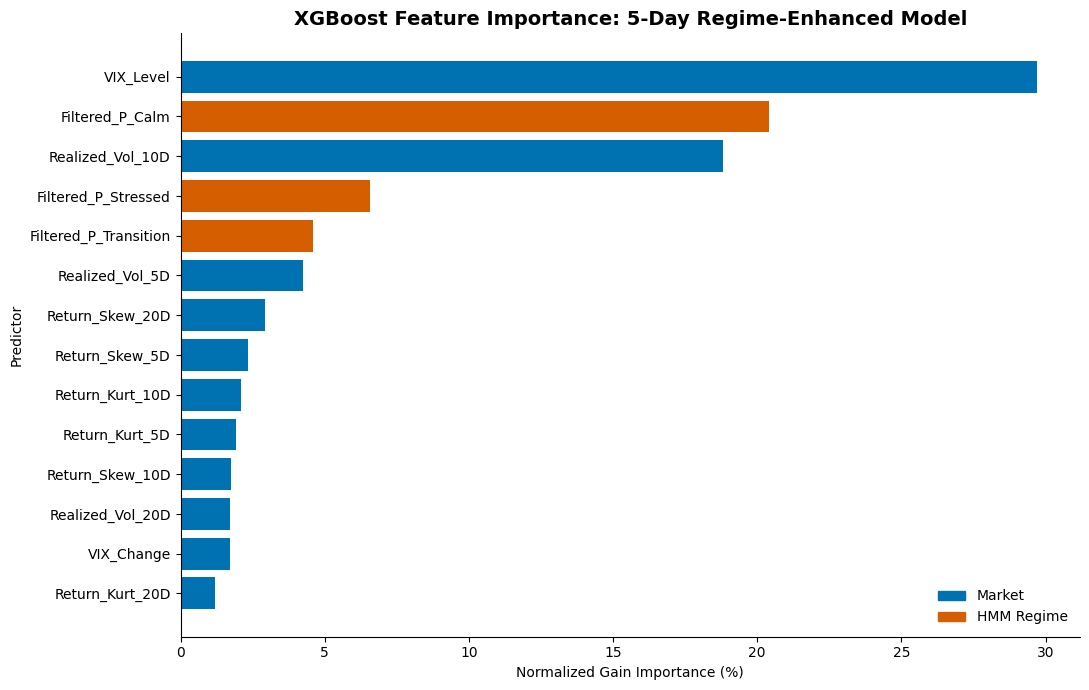

,Feature,Type,Importance (%)
0,VIX_Level,Market,29.71%
11,Filtered_P_Calm,HMM Regime,20.40%
3,Realized_Vol_10D,Market,18.83%
13,Filtered_P_Stressed,HMM Regime,6.56%
12,Filtered_P_Transition,HMM Regime,4.60%
2,Realized_Vol_5D,Market,4.23%
7,Return_Skew_20D,Market,2.92%
5,Return_Skew_5D,Market,2.34%
9,Return_Kurt_10D,Market,2.09%
8,Return_Kurt_5D,Market,1.93%


In [ ]:

# Select fitted 5-day regime-enhanced XGBoost model
xgb_hmm_5d = xgb_models[(5, "Market + HMM")]

# Retrieve gain-based feature importance
booster = xgb_hmm_5d.get_booster()
gain_scores = booster.get_score(importance_type="gain")

# Build feature importance table
feature_importance = pd.DataFrame({
    "Feature": enhanced_features,
    "Gain": [
        gain_scores.get(feature, 0.0)
        for feature in enhanced_features
    ]
})

# Normalize importance for easier interpretation
total_gain = feature_importance["Gain"].sum()

feature_importance["Importance (%)"] = (
    feature_importance["Gain"] / total_gain * 100
)

feature_importance = feature_importance.sort_values(
    "Importance (%)",
    ascending=True
)

# Distinguish regime features from market predictors
feature_importance["Type"] = np.where(
    feature_importance["Feature"].isin(regime_predictors),
    "HMM Regime",
    "Market"
)

# Color palette
feature_colors = {
    "Market": "#0072B2",
    "HMM Regime": "#D55E00"
}

# Create and store figure
fig_xgb_feature_importance, ax = plt.subplots(
    figsize=(11, 7)
)

ax.barh(
    feature_importance["Feature"],
    feature_importance["Importance (%)"],
    color=[
        feature_colors[t]
        for t in feature_importance["Type"]
    ]
)

ax.set_title(
    "XGBoost Feature Importance: 5-Day Regime-Enhanced Model",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Normalized Gain Importance (%)")
ax.set_ylabel("Predictor")

ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="#0072B2", label="Market"),
        Patch(color="#D55E00", label="HMM Regime")
    ],
    frameon=False
)

fig_xgb_feature_importance.tight_layout()
plt.show()

# Display numerical results
display(
    feature_importance[
        ["Feature", "Type", "Importance (%)"]
    ].sort_values(
        "Importance (%)",
        ascending=False
    ).style.format({
        "Importance (%)": "{:.2f}%"
    })
)


### Observation : XGBoost Test Performance and Feature Importance

- **Primary Forecasting Performance:** The market-only XGBoost model achieved a test RMSE of 0.0756 and MAE of 0.0497 for the 5-day forecast, representing a 22.41% reduction in RMSE relative to the persistence baseline.

- **Comparison with Ridge Regression:** XGBoost outperformed persistence across all three forecasting horizons but achieved higher test RMSE than Ridge Regression. This suggests that the tested regularized linear specification generalized more effectively than the nonlinear XGBoost configurations.

- **Incremental HMM Contribution:** Incorporating HMM regime probabilities increased test RMSE by 1.78%, 1.86%, and 2.35% for the 5-, 10-, and 20-day forecasting horizons, respectively. The modest validation improvements observed at the 5- and 20-day horizons did not generalize to the independent test period.

- **Volatility Tracking:** Both XGBoost specifications captured broad movements in realized volatility but substantially underestimated extreme volatility spikes, particularly during the sharp market disruption observed in 2025.

- **Feature Importance:** VIX Level exhibited the highest normalized gain importance, followed by the Calm regime probability and 10-day historical realized volatility. Although the three HMM probabilities received substantial importance within the fitted model, their inclusion did not improve out-of-sample forecasting accuracy.

- **Modeling Implications:** The results indicate that feature importance within a nonlinear model does not necessarily translate into incremental predictive value. The HMM probabilities may contain information that overlaps with existing market predictors, limiting their additional forecasting contribution under the tested specifications.

### 12 Consolidated Out of Sample Model Performance

The out of sample forecasting performance of the persistence baseline, Ridge Regression, and XGBoost is consolidated to compare predictive accuracy across model specifications and forecasting horizons.

The comparison includes market-only and regime-enhanced specifications for Ridge Regression and XGBoost, alongside the persistence baseline. All models are evaluated using the same test observations from 2022–2025.

Performance is assessed using Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE), with lower values indicating greater forecasting accuracy. The primary comparison focuses on 5-day forward realized volatility, while the 10- and 20-day horizons are examined as robustness checks.

This analysis establishes which supervised approach achieves the strongest forecasting performance and provides the foundation for assessing the incremental predictive contribution of HMM regime information.

### 12.1 Consolidate Test Results

In [ ]:

# Select independent test-period results
final_results = results[
    results["Sample"] == "Test"
].copy()

# Define model order for presentation
model_order = {
    "Persistence": 0,
    "Ridge": 1,
    "XGBoost": 2
}

feature_order = {
    "Matched trailing volatility": 0,
    "Market-only": 1,
    "Market + HMM": 2
}

# Sort by horizon, model, and feature set
final_results["Model_Order"] = (
    final_results["Model"].map(model_order)
)

final_results["Feature_Order"] = (
    final_results["Features"].map(feature_order)
)

final_results = (
    final_results
    .sort_values([
        "Horizon",
        "Model_Order",
        "Feature_Order"
    ])
    .drop(columns=["Model_Order", "Feature_Order"])
    .reset_index(drop=True)
)

# Verify expected number of configurations
assert len(final_results) == 15, (
    "Expected 15 test configurations."
)

assert not final_results.duplicated(
    ["Model", "Features", "Horizon", "Sample"]
).any(), "Duplicate model results detected."

# Display consolidated results
display(
    final_results[
        ["Horizon", "Model", "Features", "RMSE", "MAE"]
    ].style.format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}"
    })
)

,Horizon,Model,Features,RMSE,MAE
0,5,Persistence,Matched trailing volatility,0.0974,0.0647
1,5,Ridge,Market-only,0.0738,0.0492
2,5,Ridge,Market + HMM,0.0740,0.0494
3,5,XGBoost,Market-only,0.0756,0.0497
4,5,XGBoost,Market + HMM,0.0769,0.0504
5,10,Persistence,Matched trailing volatility,0.0849,0.0543
6,10,Ridge,Market-only,0.0670,0.0427
7,10,Ridge,Market + HMM,0.0673,0.0428
8,10,XGBoost,Market-only,0.0698,0.0427
9,10,XGBoost,Market + HMM,0.0711,0.0430


Visualization - Consolidate Test RMSE Preformance

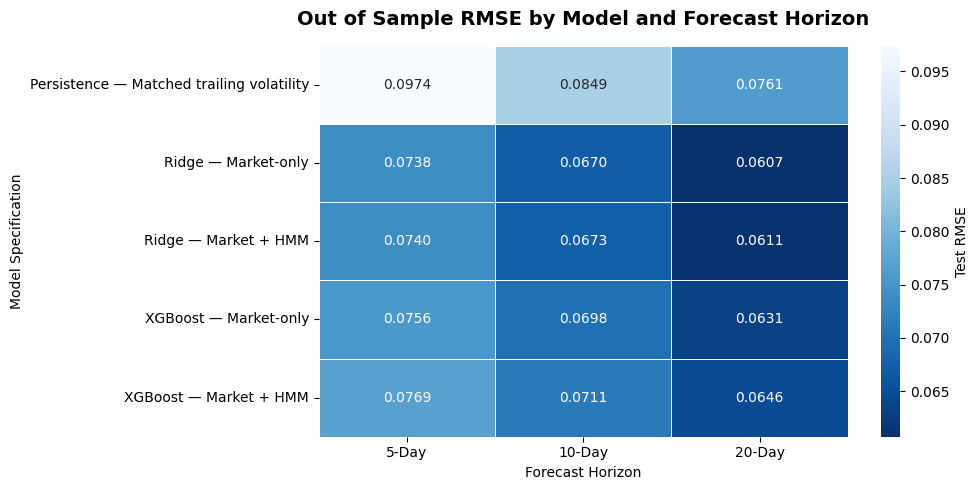

In [ ]:

# Create descriptive model labels
final_results["Model Specification"] = (
    final_results["Model"] + " — " +
    final_results["Features"]
)

# Pivot test RMSE values
rmse_matrix = final_results.pivot(
    index="Model Specification",
    columns="Horizon",
    values="RMSE"
)

# Control display order
specification_order = [
    "Persistence — Matched trailing volatility",
    "Ridge — Market-only",
    "Ridge — Market + HMM",
    "XGBoost — Market-only",
    "XGBoost — Market + HMM"
]

rmse_matrix = rmse_matrix.reindex(
    index=specification_order,
    columns=list(HORIZONS)
)

# Create and store figure
fig_final_rmse_comparison, ax = plt.subplots(
    figsize=(10, 5)
)

sns.heatmap(
    rmse_matrix,
    cmap="Blues_r",
    annot=True,
    fmt=".4f",
    linewidths=0.5,
    cbar_kws={"label": "Test RMSE"},
    ax=ax
)

ax.set_title(
    "Out of Sample RMSE by Model and Forecast Horizon",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Forecast Horizon")
ax.set_ylabel("Model Specification")

ax.set_xticklabels(["5-Day", "10-Day", "20-Day"])
ax.tick_params(axis="y", rotation=0)

fig_final_rmse_comparison.tight_layout()
plt.show()


### 12.2 Relative Forecasting Imrpovement Over Persistence
The forecasting performance of Ridge Regression and XGBoost is compared against the persistence baseline to quantify the additional predictive value of supervised learning.

For each forecasting horizon, the percentage reduction in RMSE relative to persistence is calculated. Positive improvements indicate lower forecasting errors than the baseline, while negative values indicate weaker performance.

The comparison is conducted using identical test observations within each forecasting horizon, allowing the relative benefits of different model specifications to be assessed consistently.

In [ ]:

# Extract persistence RMSE by horizon
persistence_rmse = (
    final_results[
        final_results["Model"] == "Persistence"
    ]
    .set_index("Horizon")["RMSE"]
)

# Select supervised models
supervised_results = final_results[
    final_results["Model"].isin(["Ridge", "XGBoost"])
].copy()

# Calculate improvement over persistence
supervised_results["RMSE_Improvement_%"] = (
    1 - supervised_results["RMSE"] /
    supervised_results["Horizon"].map(persistence_rmse)
) * 100

# Create comparison table
rmse_improvement_table = supervised_results.pivot(
    index=["Model", "Features"],
    columns="Horizon",
    values="RMSE_Improvement_%"
)

rmse_improvement_table = rmse_improvement_table.reindex(
    columns=list(HORIZONS)
)

display(
    rmse_improvement_table.style.format("{:+.2f}%")
)

Visualization - Improvement Over Persistence

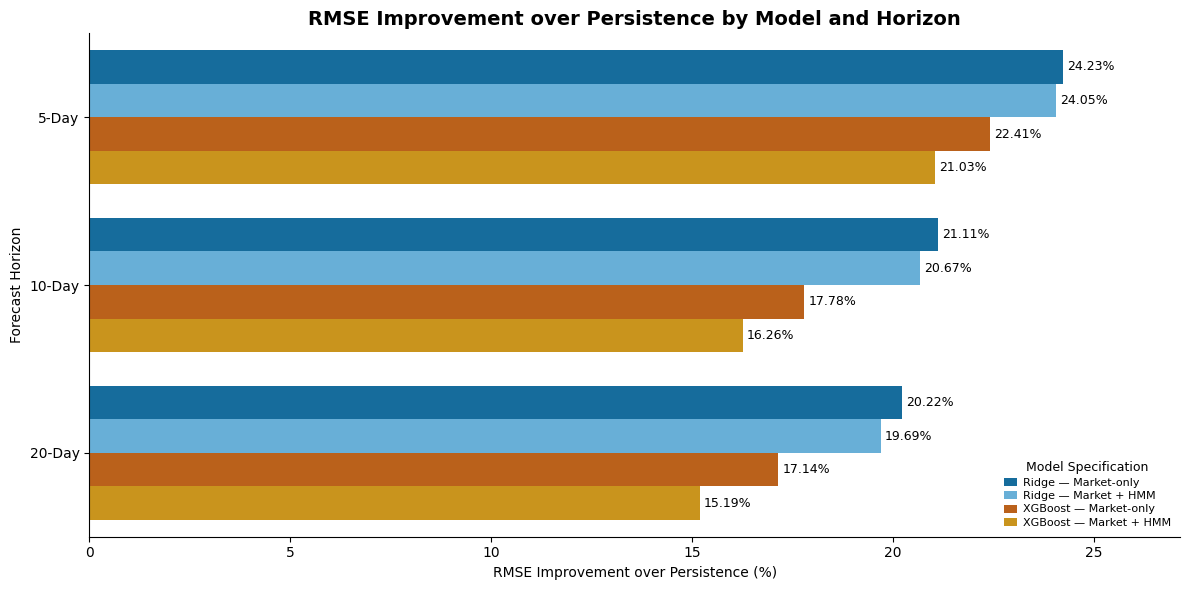

In [ ]:

# Create descriptive labels
plot_df = supervised_results.copy()

plot_df["Specification"] = (
    plot_df["Model"] + " — " + plot_df["Features"]
)

# Consistent color-blind-friendly palette
model_palette = {
    "Ridge — Market-only": "#0072B2",
    "Ridge — Market + HMM": "#56B4E9",
    "XGBoost — Market-only": "#D55E00",
    "XGBoost — Market + HMM": "#E69F00"
}

# Create and store figure
fig_relative_rmse_improvement, ax = plt.subplots(
    figsize=(12, 6)
)

sns.barplot(
    data=plot_df,
    y="Horizon",
    x="RMSE_Improvement_%",
    hue="Specification",
    hue_order=list(model_palette),
    palette=model_palette,
    orient="h",
    native_scale=False,
    errorbar=None,
    ax=ax
)
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        label_type="edge",
        padding=3,
        fontsize=9
    )

# Allow space for percentage labels
ax.set_xlim(
    0,
    plot_df["RMSE_Improvement_%"].max() * 1.12
)

ax.set_title(
    "RMSE Improvement over Persistence by Model and Horizon",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("RMSE Improvement over Persistence (%)")
ax.set_ylabel("Forecast Horizon")

ax.set_yticklabels(["5-Day", "10-Day", "20-Day"])

ax.legend(
    title="Model Specification",
    loc="lower right",
    fontsize=8,
    title_fontsize=9,
    frameon=False,
    handlelength=1.2,
    handleheight=0.7,
    handletextpad=0.5,
    labelspacing=0.3,
    borderpad=0.3,
    ncol=1
)

ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

fig_relative_rmse_improvement.tight_layout()
plt.show()


### 12.3 Incremental Contribution of HMM Regime Information

The incremental predictive contribution of the HMM regime probabilities is evaluated by comparing the market-only and regime-enhanced specifications of Ridge Regression and XGBoost.

For each model and forecasting horizon, the percentage change in RMSE resulting from the inclusion of HMM probabilities is calculated using the independent test dataset. Positive values indicate an improvement in forecasting accuracy, while negative values indicate a deterioration relative to the market-only specification.

This comparison isolates the observed performance difference associated with incorporating regime information under each modeling approach. The primary analysis focuses on the 5-day forecasting horizon, with 10- and 20-day results used to assess whether the findings remain consistent across longer horizons.

In [ ]:

# Select supervised model results
hmm_results = final_results[
    final_results["Model"].isin(["Ridge", "XGBoost"])
].copy()

# Compare market-only vs. regime-enhanced RMSE
hmm_comparison = hmm_results.pivot(
    index=["Model", "Horizon"],
    columns="Features",
    values="RMSE"
).reset_index()

# Calculate incremental RMSE improvement
hmm_comparison["HMM_Improvement_%"] = (
    1 - hmm_comparison["Market + HMM"] /
    hmm_comparison["Market-only"]
) * 100

# Rename columns for presentation
hmm_comparison = hmm_comparison.rename(columns={
    "Market-only": "Market_Only_RMSE",
    "Market + HMM": "Market_HMM_RMSE"
})

# Sort results
hmm_comparison = hmm_comparison.sort_values(
    ["Horizon", "Model"]
).reset_index(drop=True)

display(
    hmm_comparison.style.format({
        "Market_Only_RMSE": "{:.4f}",
        "Market_HMM_RMSE": "{:.4f}",
        "HMM_Improvement_%": "{:+.2f}%"
    })
)


Features,Model,Horizon,Market_HMM_RMSE,Market_Only_RMSE,HMM_Improvement_%
0,Ridge,5,0.0740,0.0738,-0.24%
1,XGBoost,5,0.0769,0.0756,-1.78%
2,Ridge,10,0.0673,0.0670,-0.56%
3,XGBoost,10,0.0711,0.0698,-1.86%
4,Ridge,20,0.0611,0.0607,-0.66%
5,XGBoost,20,0.0646,0.0631,-2.35%


Visualization - Incremental HMM Improvement Across Models

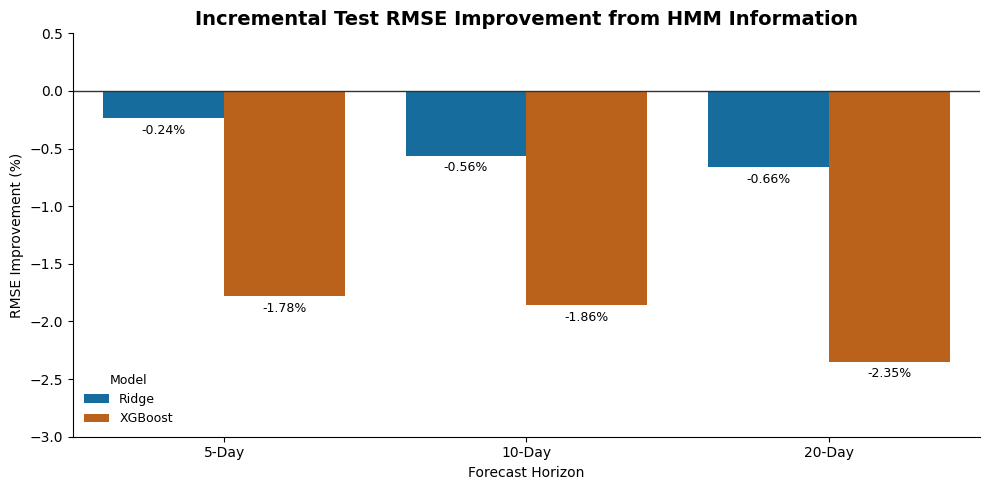

In [ ]:

# Prepare comparison data
plot_hmm = hmm_comparison.copy()

# Consistent model colors
hmm_palette = {
    "Ridge": "#0072B2",
    "XGBoost": "#D55E00"
}

# Create and store figure
fig_final_hmm_improvement, ax = plt.subplots(
    figsize=(10, 5)
)

sns.barplot(
    data=plot_hmm,
    x="Horizon",
    y="HMM_Improvement_%",
    hue="Model",
    order=list(HORIZONS),
    hue_order=["Ridge", "XGBoost"],
    palette=hmm_palette,
    errorbar=None,
    ax=ax
)

# Add percentage labels to each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%+.2f%%",
        label_type="edge",
        padding=4,
        fontsize=9
    )

# Reference line at zero
ax.axhline(0, color="#333333", linewidth=1)

ax.set_title(
    "Incremental Test RMSE Improvement from HMM Information",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Forecast Horizon")
ax.set_ylabel("RMSE Improvement (%)")
ax.set_xticklabels(["5-Day", "10-Day", "20-Day"])

# Leave room for negative labels
ax.set_ylim(
    min(-3, plot_hmm["HMM_Improvement_%"].min() * 1.25),
    0.5
)

# Compact legend
ax.legend(
    title="Model",
    fontsize=9,
    title_fontsize=9,
    frameon=False,
    loc="lower left"
)

ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

fig_final_hmm_improvement.tight_layout()
plt.show()


### Observation : Incremental Contribution

1. HMM information consistently reduces forecasting accuracy. All six comparisons produce negative improvements, indicating that the addition of regime probabilities increases test RMSE relative to the corresponding market-only model.
2. The deterioration is larger for XGBoost. At the primary 5-day horizon, HMM information increases XGBoost RMSE by approximately 1.78%, compared with just 0.24% for Ridge. This suggests that the tested nonlinear model does not extract additional generalizable predictive value from the regime probabilities.
3. The deterioration increases slightly with the forecasting horizon. Both models exhibit progressively larger negative improvements from 5 to 20 days, although these small differences are insufficient to establish a statistically meaningful horizon effect.
The results are consistent with our earlier finding that the HMM probabilities are strongly related to existing market characteristics, particularly VIX and historical realized volatility. They may therefore provide limited additional information once those predictors are already included.
Importantly, this does not invalidate Model B's regime classifications. It indicates that the inferred regimes did not provide incremental forecasting improvements under the supervised specifications tested.

### 12.4 Statistical Comparison of Forecast Accuracy

A Diebold–Mariano-style forecast comparison test is conducted to determine whether differences in out-of-sample forecasting accuracy are statistically significant.

The test compares the squared forecasting errors of two competing models over the independent 2022–2025 test period. A Newey–West heteroskedasticity-and-autocorrelation-consistent (HAC) variance estimate is applied to account for potential serial dependence arising from overlapping forward volatility windows.

For each trading date, the difference in squared forecasting errors is calculated as:

**Loss Difference = (Error of Model A)² − (Error of Model B)²**

Where:

- **Error of Model A:** Actual volatility minus Model A's predicted volatility.
- **Error of Model B:** Actual volatility minus Model B's predicted volatility.
- **Loss Difference:** Difference between the two models' squared forecasting errors for the same trading date.

The resulting values are interpreted as follows:

- **Positive average loss difference:** Model B produces lower average squared forecasting errors.
- **Negative average loss difference:** Model A produces lower average squared forecasting errors.
- **Average loss difference equal to zero:** The models have equal average squared forecasting loss.

The **null hypothesis (H₀)** states that the expected loss difference between the two models is zero, indicating equal expected forecasting accuracy.

The test statistic is calculated as:

**Test Statistic = Average Loss Difference / HAC-Adjusted Standard Error**

Statistical significance is evaluated using a two-sided normal approximation at the 5% significance level (p-value < 0.05).

A statistically significant result provides evidence that the models differ in expected squared forecasting loss, while a non-significant result indicates insufficient evidence to reject equal expected forecasting loss.

The analysis compares Ridge Regression against persistence and evaluates whether incorporating HMM regime probabilities improves Ridge Regression and XGBoost across the 5-, 10-, and 20-day forecasting horizons.


In [ ]:
# Diebold-Mariano-style test using HAC standard errors
def dm_hac_test(forecast_a, forecast_b, horizon):

    # Align forecasts on trading dates
    paired = pd.concat(
        [
            forecast_a.set_index("Date")[
                ["Actual", "Predicted"]
            ].rename(columns={
                "Actual": "Actual_A",
                "Predicted": "Pred_A"
            }),
            forecast_b.set_index("Date")[
                ["Actual", "Predicted"]
            ].rename(columns={
                "Actual": "Actual_B",
                "Predicted": "Pred_B"
            })
        ],
        axis=1,
        join="inner"
    ).dropna()

    assert paired.index.is_unique
    assert len(paired) > horizon

    assert np.allclose(
        paired["Actual_A"],
        paired["Actual_B"]
    ), "Forecast targets do not match."

    # Squared forecasting errors
    error_a = paired["Actual_A"] - paired["Pred_A"]
    error_b = paired["Actual_B"] - paired["Pred_B"]

    # Positive means Model B has lower squared loss
    loss_diff = error_a**2 - error_b**2

    # Estimate mean loss difference with HAC covariance
    X = np.ones((len(loss_diff), 1))

    fitted = sm.OLS(
        loss_diff.to_numpy(),
        X
    ).fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags": horizon - 1,
            "use_correction": True
        },
        use_t=False
    )

    return {
        "Observations": len(paired),
        "Mean_Loss_Diff": float(fitted.params[0]),
        "DM_Statistic": float(fitted.tvalues[0]),
        "P_Value": float(fitted.pvalues[0])
    }


In [ ]:

# Define model comparisons
dm_comparisons = [
    (
        "Ridge vs Persistence",
        ("Persistence", "Matched trailing volatility"),
        ("Ridge", "Market-only")
    ),
    (
        "HMM Contribution: Ridge",
        ("Ridge", "Market-only"),
        ("Ridge", "Market + HMM")
    ),
    (
        "HMM Contribution: XGBoost",
        ("XGBoost", "Market-only"),
        ("XGBoost", "Market + HMM")
    )
]

dm_records = []

for h in HORIZONS:

    for comparison_name, model_a, model_b in dm_comparisons:

        # Select paired test forecasts
        forecast_a = forecasts[
            (forecasts["Model"] == model_a[0]) &
            (forecasts["Features"] == model_a[1]) &
            (forecasts["Horizon"] == h) &
            (forecasts["Sample"] == "Test")
        ]

        forecast_b = forecasts[
            (forecasts["Model"] == model_b[0]) &
            (forecasts["Features"] == model_b[1]) &
            (forecasts["Horizon"] == h) &
            (forecasts["Sample"] == "Test")
        ]

        test_result = dm_hac_test(
            forecast_a,
            forecast_b,
            horizon=h
        )

        dm_records.append({
            "Horizon": h,
            "Comparison": comparison_name,
            **test_result
        })

# Consolidate results
dm_results = pd.DataFrame(dm_records)

# Add statistical significance classification
dm_results["Significant_5pct"] = (
    dm_results["P_Value"] < 0.05
)

display(
    dm_results.style.format({
        "Mean_Loss_Diff": "{:+.6f}",
        "DM_Statistic": "{:+.3f}",
        "P_Value": "{:.4f}"
    })
)


,Horizon,Comparison,Observations,Mean_Loss_Diff,DM_Statistic,P_Value,Significant_5pct
0,5,Ridge vs Persistence,983,+0.004041,+3.233,0.0012,True
1,5,HMM Contribution: Ridge,983,-0.000026,-0.654,0.5133,False
2,5,HMM Contribution: XGBoost,983,-0.000205,-1.742,0.0815,False
3,10,Ridge vs Persistence,983,+0.002720,+2.088,0.0368,True
4,10,HMM Contribution: Ridge,983,-0.000050,-1.186,0.2357,False
5,10,HMM Contribution: XGBoost,983,-0.000183,-1.259,0.2079,False
6,20,Ridge vs Persistence,983,+0.002106,+1.568,0.1169,False
7,20,HMM Contribution: Ridge,983,-0.000049,-1.111,0.2667,False
8,20,HMM Contribution: XGBoost,983,-0.000189,-1.507,0.1318,False


Visualization - Forecast Preformance  

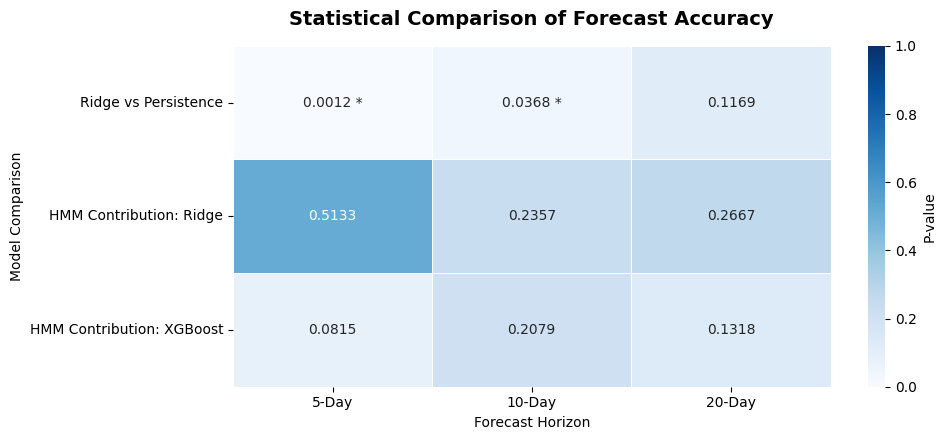

In [ ]:

# Create p-value matrix
pvalue_matrix = dm_results.pivot(
    index="Comparison",
    columns="Horizon",
    values="P_Value"
)

pvalue_matrix = pvalue_matrix.reindex(
    index=[
        "Ridge vs Persistence",
        "HMM Contribution: Ridge",
        "HMM Contribution: XGBoost"
    ],
    columns=list(HORIZONS)
)

# Create readable cell annotations
pvalue_labels = pvalue_matrix.map(
    lambda p: f"{p:.4f}" + (" *" if p < 0.05 else "")
)

# Create and store figure
fig_dm_significance, ax = plt.subplots(
    figsize=(10, 4.5)
)

sns.heatmap(
    pvalue_matrix,
    annot=pvalue_labels,
    fmt="",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "P-value"},
    ax=ax
)

ax.set_title(
    "Statistical Comparison of Forecast Accuracy",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Forecast Horizon")
ax.set_ylabel("Model Comparison")
ax.set_xticklabels(["5-Day", "10-Day", "20-Day"])
ax.tick_params(axis="y", rotation=0)

fig_dm_significance.tight_layout()
plt.show()


### Observation : Forecast Preformance
1. Ridge Regression significantly outperforms persistence at shorter horizons.
The 5-day forecast produces a p-value of 0.0012, providing strong evidence that market-only Ridge Regression achieves lower expected squared forecasting loss than persistence.
The 10-day comparison is also significant at the unadjusted 5% level (p = 0.0368). However, the 20-day result is not statistically significant (p = 0.1169).
2. HMM regime information does not produce statistically significant improvements.
None of the six HMM comparisons produces a p-value below 0.05. Although adding regime probabilities increases test RMSE in both models, the statistical tests do not establish that these differences are distinguishable from zero.
3. The primary 5-day result is the strongest finding.
After applying a Bonferroni correction across all nine comparisons, the 5-day Ridge-versus-persistence result remains significant, whereas the 10-day result does not. This provides stronger support for our primary forecasting objective than for the longer-horizon robustness checks.



### Observation : Final Model Comparison

- **Primary Forecasting Performance:** Market-only Ridge Regression achieved the lowest test RMSE (0.0738) and MAE (0.0490) for the primary 5-day forecasting horizon, reducing RMSE by approximately 24.3% relative to persistence.

- **Supervised Model Comparison:** Both Ridge Regression and XGBoost outperformed the persistence baseline across all three forecasting horizons. However, Ridge consistently achieved lower test RMSE, suggesting that the regularized linear specification generalized more effectively than the tested nonlinear configurations.

- **Incremental HMM Contribution:** Incorporating HMM regime probabilities increased test RMSE across both supervised models and all three horizons. The deterioration ranged from 0.24% to 0.66% for Ridge and 1.78% to 2.35% for XGBoost, indicating that regime information did not provide incremental forecasting improvements under the tested specifications.

- **Statistical Significance:** HAC-adjusted forecast comparisons identified statistically significant improvements for Ridge over persistence at the 5-day (p = 0.0012) and 10-day (p = 0.0368) horizons at the unadjusted 5% level. Only the primary 5-day improvement remained significant after a Bonferroni correction across nine comparisons.

- **HMM Statistical Contribution:** None of the six HMM comparisons produced statistically significant differences in expected squared forecasting loss at the 5% level. Consequently, the observed deterioration from incorporating regime probabilities cannot be interpreted as conclusive evidence that HMM information reduces forecasting accuracy.

- **Modeling Implications:** The findings demonstrate that engineered market characteristics provide useful predictive information beyond volatility persistence. However, the inferred market regimes do not demonstrate additional out-of-sample forecasting value under the tested Ridge and XGBoost specifications. This distinction highlights the difference between identifying meaningful market regimes and establishing their incremental predictive utility.

## 13. Model A : Conslusions and Limitations

### 13.1 Key Findings

Model A evaluated whether incorporating market regime information generated by Model B improves forward realized volatility forecasting. The primary analysis focused on a 5-day forecasting horizon, while 10- and 20-day forecasts served as robustness checks.

Three forecasting approaches were evaluated: a persistence baseline, Ridge Regression, and XGBoost. The supervised models were estimated using market-only predictors and regime-enhanced specifications incorporating filtered HMM probabilities.

The main findings are summarized below:

- **Forecasting Performance:** Both Ridge Regression and XGBoost outperformed the persistence baseline across all three horizons. Market-only Ridge Regression achieved the lowest test RMSE, with a 24.3% improvement over persistence at the primary 5-day horizon.

- **Nonlinear Modeling:** XGBoost achieved lower validation RMSE than Ridge Regression, but this advantage did not generalize to the independent test period. The tested regularized linear model consistently achieved better out-of-sample forecasting accuracy.

- **Incremental Regime Information:** Adding HMM regime probabilities did not improve test RMSE for either supervised model across the three horizons. The deterioration was relatively small for Ridge Regression and more pronounced for XGBoost.

- **Statistical Evidence:** HAC-adjusted forecast comparisons indicated that market-only Ridge Regression significantly outperformed persistence at the primary 5-day horizon (p = 0.0012). However, no statistically significant incremental forecasting benefit was identified from incorporating HMM probabilities.

Overall, the findings demonstrate that engineered market characteristics provide useful information for forecasting future volatility, while inferred market regime probabilities do not offer additional predictive improvements under the tested specifications.

### 13.2 Methodological Limitations

Several limitations should be considered when interpreting the results:

- **Historical Evaluation Period:** The analysis uses historical S&P 500 and VIX observations through 2025. Forecasting performance may vary under future market conditions or structural changes not represented in the sample.

- **Regime Information Redundancy:** The HMM regime probabilities are derived from market characteristics that overlap with the supervised predictors, particularly VIX and historical realized volatility. This may limit their incremental predictive contribution.

- **Model Specifications:** Ridge Regression and XGBoost were evaluated using predefined feature sets and limited hyperparameter searches. Alternative specifications, feature interactions, or forecasting approaches may produce different results.

- **Overlapping Forecast Windows:** Forward realized volatility targets use overlapping trading-day windows, creating serial dependence among forecasting errors. Although boundary purges and HAC-adjusted statistical tests were applied, the resulting inference remains sensitive to the chosen variance-estimation assumptions.

- **Statistical Interpretation:** The absence of statistically significant improvements from HMM probabilities does not establish that regime information has no predictive value under all market conditions or alternative model specifications.

These limitations suggest that the findings should be interpreted as evidence regarding the specific models, features, and historical evaluation periods examined rather than universal conclusions about volatility forecasting.

### 13.3 Implications for the Overall Project

The overall project combines unsupervised market regime identification with supervised volatility forecasting to investigate whether inferred market states provide additional predictive information beyond observable market characteristics.

Model B identified three interpretable market regimes—Calm, Transition, and Stressed—using a Gaussian Hidden Markov Model. These regimes provide a structured description of historical market conditions, including differences in volatility levels and regime persistence.

Model A extended this analysis by incorporating the filtered HMM regime probabilities into Ridge Regression and XGBoost forecasting models.

Although the regime probabilities were associated with future realized volatility and received substantial feature importance within XGBoost, their inclusion did not improve out-of-sample forecasting accuracy. This highlights an important distinction between identifying meaningful patterns in market data and demonstrating their incremental predictive value.

The results suggest that the regime information may summarize characteristics already captured by VIX and historical realized volatility. Nevertheless, the unsupervised approach remains useful for characterizing market conditions and examining how volatility dynamics differ across inferred states.

The project therefore demonstrates both the potential and limitations of combining unsupervised learning with supervised forecasting. **Market regime identification provides an interpretable representation of market behavior, but its predictive contribution must be independently validated rather than assumed.**

--------------------------------------------------------------------------------

## Misc

### Save Visuals

In [ ]:
from pathlib import Path

In [ ]:
# Create output directory
output_dir = Path("Model_A_Visualizations")
output_dir.mkdir(parents=True, exist_ok=True)

# Figure names and notebook variables
figure_registry = {
    # Section 6: Forecasting targets
    "6_3_Forward_RV_TimeSeries": "fig_forward_rv_timeseries",
    "6_4_Forward_RV_Distribution": "fig_forward_rv_distribution",
    "6_4_Forward_RV_Boxplot": "fig_forward_rv_boxplot",

    # Section 7: Predictor diagnostics
    "7_3_Predictor_Correlation": "fig_predictor_corr",
    "7_3_Predictor_Target_Correlation": "fig_predictor_target_corr",

    # Section 8: Chronological splitting
    "8_3_Chronological_Split": "fig_chronological_split",

    # Section 9: Persistence baseline
    "9_4_Persistence_5D": "fig_persistence_5d",
    "9_4_Persistence_Errors": "fig_persistence_errors",

    # Section 10: Ridge regression
    "10_3_Ridge_Tuning": "fig_ridge_tuning",
    "10_6_Ridge_5D_Predictions": "fig_ridge_5d_predictions",
    "10_6_Ridge_HMM_Improvement": "fig_ridge_hmm_improvement",

    # Section 11: XGBoost
    "11_4_XGBoost_Tuning": "fig_xgb_tuning",
    "11_4_XGBoost_HMM_Validation": "fig_xgb_hmm_improvement",
    "11_5_XGBoost_5D_Predictions": "fig_xgb_5d_predictions",
    "11_5_XGBoost_HMM_Test": "fig_xgb_hmm_test_improvement",
    "11_6_XGBoost_Feature_Importance": "fig_xgb_feature_importance",

    # Section 12: Final comparison
    "12_1_Final_RMSE_Comparison": "fig_final_rmse_comparison",
    "12_2_Improvement_Over_Persistence": "fig_relative_rmse_improvement",
    "12_3_Final_HMM_Improvement": "fig_final_hmm_improvement",
    "12_4_DM_Significance": "fig_dm_significance"
}

# Export figures individually
saved_files = []
missing_figures = []

for filename, variable_name in figure_registry.items():

    fig = globals().get(variable_name)

    if isinstance(fig, plt.Figure):
        filepath = output_dir / f"{filename}.png"

        fig.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        saved_files.append(filepath)

    else:
        missing_figures.append(variable_name)

print(f"Figures saved: {len(saved_files)}")
print(f"Figures unavailable: {len(missing_figures)}")
print(f"Output directory: {output_dir.resolve()}")

if missing_figures:
    print("\nFigures to regenerate:")
    for name in missing_figures:
        print("-", name)


Figures saved: 18
Figures unavailable: 2
Output directory: /content/Model_A_Visualizations

Figures to regenerate:
- fig_persistence_5d
- fig_persistence_errors
